### Notebook structure

`exploration.py` contains preparation, PCA fitting, and reusable plotting functions. This notebook chooses which views to display and explains the results. For example, `exploration.plot_pca_scatter(analysis, group="benign", zoom=True)` shows the benign zoom using the existing fitted PCA. Helper functions take explicit inputs and keep temporary plotting data local, so unrelated cells do not share scratch variables. The PCA result object keeps fitted models and aligned data together; `analysis.X_pca` preserves input feature order.


In [1]:
import exploration

In [2]:
df = exploration.load_dataset("dataset.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64239 entries, 0 to 64238
Data columns (total 88 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   64239 non-null  int64  
 1   Flow ID                      64239 non-null  str    
 2   Source IP                    64239 non-null  str    
 3   Source Port                  64239 non-null  int64  
 4   Destination IP               64239 non-null  str    
 5   Destination Port             64239 non-null  int64  
 6   Protocol                     64239 non-null  str    
 7   Timestamp                    64239 non-null  str    
 8   Flow Duration                64239 non-null  int64  
 9   Total Fwd Packets            64239 non-null  int64  
 10  Total Backward Packets       64239 non-null  int64  
 11  Total Length of Fwd Packets  64239 non-null  float64
 12  Total Length of Bwd Packets  64239 non-null  float64
 13  Fwd Packet Length Max      

/Users/lents/coding/polito/projects/ml/exploration.py:23: DtypeWarning: Columns (85: SimillarHTTP) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


In [3]:
df.head(10)

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,label
0,0,172.16.0.5-192.168.50.1-634-60495-17,172.16.0.5,634,192.168.50.1,60495,UDP,2018-12-01 10:51:39.813448,28415,97,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
1,1,172.16.0.5-192.168.50.1-60495-634-17,192.168.50.1,634,172.16.0.5,60495,UDP,2018-12-01 10:51:39.820842,2,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,ddos_dns
2,2,172.16.0.5-192.168.50.1-634-46391-17,172.16.0.5,634,192.168.50.1,46391,UDP,2018-12-01 10:51:39.852499,48549,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
3,3,172.16.0.5-192.168.50.1-634-11894-17,172.16.0.5,634,192.168.50.1,11894,UDP,2018-12-01 10:51:39.890213,48337,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
4,4,172.16.0.5-192.168.50.1-634-27878-17,172.16.0.5,634,192.168.50.1,27878,UDP,2018-12-01 10:51:39.941151,32026,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
5,5,172.16.0.5-192.168.50.1-634-47149-17,172.16.0.5,634,192.168.50.1,47149,UDP,2018-12-01 10:51:39.942030,46469,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
6,6,172.16.0.5-192.168.50.1-634-22713-17,172.16.0.5,634,192.168.50.1,22713,UDP,2018-12-01 10:51:39.973650,31201,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
7,7,172.16.0.5-192.168.50.1-634-49912-17,172.16.0.5,634,192.168.50.1,49912,UDP,2018-12-01 10:51:39.994394,50453,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
8,8,172.16.0.5-192.168.50.1-634-56681-17,172.16.0.5,634,192.168.50.1,56681,UDP,2018-12-01 10:51:40.005191,31008,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
9,9,172.16.0.5-192.168.50.1-634-13161-17,172.16.0.5,634,192.168.50.1,13161,UDP,2018-12-01 10:51:40.036581,30143,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns


In [4]:
df.describe()

,Unnamed: 0,Source Port,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Inbound
count,64239.000000,64239.000000,64239.000000,6.423900e+04,64239.000000,64239.000000,64239.000000,6.423900e+04,64239.000000,64239.000000,...,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,64239.000000
mean,32637.819876,25267.368608,30715.252884,5.150614e+06,18.814848,1.304036,6699.521630,2.153348e+03,613.992948,588.863043,...,-4.167229e+07,9.026629e+03,4.878774e+03,1.687791e+04,6.204895e+03,1.155553e+06,2.613584e+05,1.555321e+06,8.908522e+05,0.919566
std,19008.473731,24710.413442,20347.990914,2.249713e+07,462.305336,25.199720,20510.320389,9.087201e+04,585.691655,584.276284,...,2.062767e+08,2.045563e+05,1.424082e+05,3.828583e+05,1.667756e+05,5.341380e+06,1.574889e+06,6.993415e+06,4.571276e+06,0.271966
min,0.000000,0.000000,0.000000,1.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,...,-1.062719e+09,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,16209.500000,779.000000,12435.500000,1.000000e+00,2.000000,0.000000,123.000000,0.000000e+00,53.000000,36.000000,...,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
50%,32477.000000,29661.000000,30797.000000,2.000000e+00,2.000000,0.000000,1050.000000,0.000000e+00,393.000000,375.000000,...,1.400000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
75%,48726.500000,48510.500000,49041.500000,2.087700e+04,2.000000,0.000000,2944.000000,0.000000e+00,1464.000000,1464.000000,...,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
max,65999.000000,65518.000000,65535.000000,1.200000e+08,85894.000000,1862.000000,176000.000000,8.829488e+06,3564.000000,2020.000000,...,1.480000e+03,1.678654e+07,2.853681e+07,6.783473e+07,8.349846e+06,1.147455e+08,5.275036e+07,1.147455e+08,1.147455e+08,1.000000


In [5]:
df_stripped, columns_to_drop = exploration.prepare_features(df)
columns_to_drop

['Bwd PSH Flags',
 'Fwd URG Flags',
 'Bwd URG Flags',
 'FIN Flag Count',
 'PSH Flag Count',
 'ECE Flag Count',
 'Fwd Avg Bytes/Bulk',
 'Fwd Avg Packets/Bulk',
 'Fwd Avg Bulk Rate',
 'Bwd Avg Bytes/Bulk',
 'Bwd Avg Packets/Bulk',
 'Bwd Avg Bulk Rate']

In [6]:
df_stripped.describe()

,Source Port,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Inbound,Protocol_HOPOPT,Protocol_TCP,Protocol_UDP
count,64239.000000,64239.000000,6.423900e+04,64239.000000,64239.000000,64239.000000,6.423900e+04,64239.000000,64239.000000,64239.000000,...,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,64239.000000,64239.000000,64239.000000,64239.000000
mean,25267.368608,30715.252884,5.150614e+06,18.814848,1.304036,6699.521630,2.153348e+03,613.992948,588.863043,597.433678,...,1.687791e+04,6.204895e+03,1.155553e+06,2.613584e+05,1.555321e+06,8.908522e+05,0.919566,0.000903,0.238344,0.760753
std,24710.413442,20347.990914,2.249713e+07,462.305336,25.199720,20510.320389,9.087201e+04,585.691655,584.276284,579.518758,...,3.828583e+05,1.667756e+05,5.341380e+06,1.574889e+06,6.993415e+06,4.571276e+06,0.271966,0.030035,0.426074,0.426627
min,0.000000,0.000000,1.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,779.000000,12435.500000,1.000000e+00,2.000000,0.000000,123.000000,0.000000e+00,53.000000,36.000000,50.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000,1.000000
50%,29661.000000,30797.000000,2.000000e+00,2.000000,0.000000,1050.000000,0.000000e+00,393.000000,375.000000,383.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000,1.000000
75%,48510.500000,49041.500000,2.087700e+04,2.000000,0.000000,2944.000000,0.000000e+00,1464.000000,1464.000000,1464.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000,1.000000
max,65518.000000,65535.000000,1.200000e+08,85894.000000,1862.000000,176000.000000,8.829488e+06,3564.000000,2020.000000,2666.086957,...,6.783473e+07,8.349846e+06,1.147455e+08,5.275036e+07,1.147455e+08,1.147455e+08,1.000000,1.000000,1.000000,1.000000


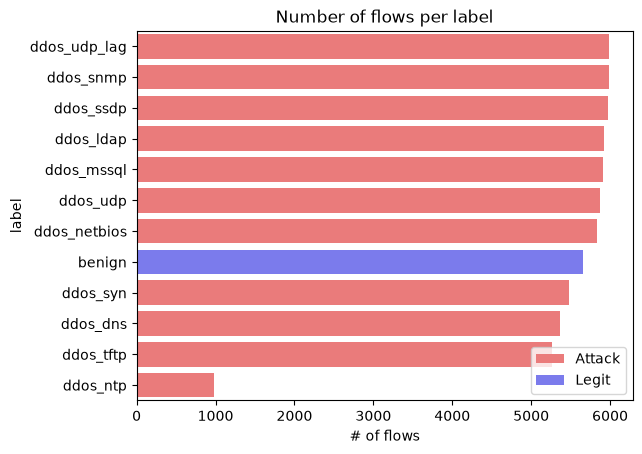

In [7]:
exploration.plot_class_counts(df_stripped)

### What the traffic classes mean

DDoS means distributed denial of service: overwhelming a target with traffic so legitimate users cannot use it. Reflection sends requests with the victim's address as the source, causing other servers to reply to the victim. Amplification means those replies are larger than the requests.

| Class | Brief explanation |
| --- | --- |
| `benign` | Normal traffic, not labeled as an attack. |
| `ddos_dns` | Abuses Domain Name System servers to reflect and amplify traffic toward the victim. |
| `ddos_ldap` | Abuses directory-service responses, commonly through connectionless LDAP, to flood the victim. |
| `ddos_mssql` | Abuses Microsoft SQL Server discovery responses to reflect traffic toward the victim. |
| `ddos_netbios` | Abuses NetBIOS name-service responses to flood the victim. |
| `ddos_ntp` | Abuses Network Time Protocol servers to reflect and amplify traffic. |
| `ddos_snmp` | Abuses Simple Network Management Protocol responses to flood the victim. |
| `ddos_ssdp` | Abuses Simple Service Discovery Protocol responses from discoverable devices to flood the victim. |
| `ddos_syn` | Floods TCP connection requests, exhausting resources used for incomplete connections. |
| `ddos_tftp` | Abuses Trivial File Transfer Protocol responses to flood the victim. |
| `ddos_udp` | Sends many UDP packets to consume bandwidth or processing capacity. |
| `ddos_udp_lag` | A UDP flood variant intended to cause delay and service disruption. |

For example, a DNS reflection attack causes DNS servers to send replies to the victim instead of the attacker. These descriptions explain the attack families; the labels alone do not establish the exact mechanism of every flow. The bars count recorded flows, not separate attack incidents.

Reference for the attack families: [Canadian Institute for Cybersecurity, CICDDoS2019](https://www.unb.ca/cic/datasets/ddos-2019.html).


### Protocol composition by traffic class

Each stacked bar shows the percentage of flows using each protocol within a class and totals 100%. For example, an 80% UDP segment means 80% of that class's flows use UDP. This compares protocol mix independently of class size. Shares below 5% are left unlabeled to avoid overlapping text; their values remain available in `protocol_percentages`.


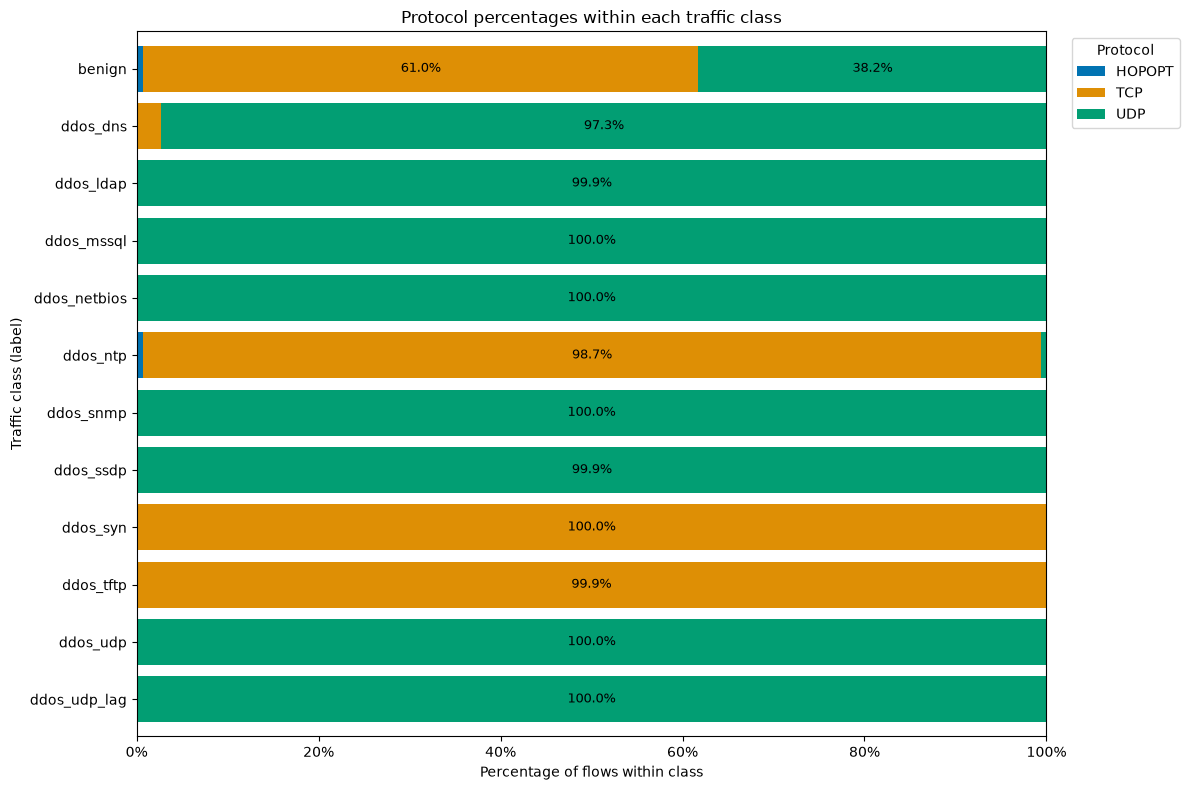

In [8]:
protocol_percentages = exploration.plot_protocol_percentages(df)

### Feature distributions by traffic class

These box plots compare the median, middle 50% of values, and outliers for each traffic class. For example, compare median packet rates between benign traffic and attack classes using the line inside each box.

Strongly skewed features use a symmetric logarithmic y-axis, labeled on the plot. This scale is linear from 0 to 1 and logarithmic above 1, so zeros remain visible. The y-axis starts at -1, or -10^0, to leave a small margin below zero. Boxes are calculated from the original values. Missing or infinite values are excluded separately for each feature in a plotting copy only.


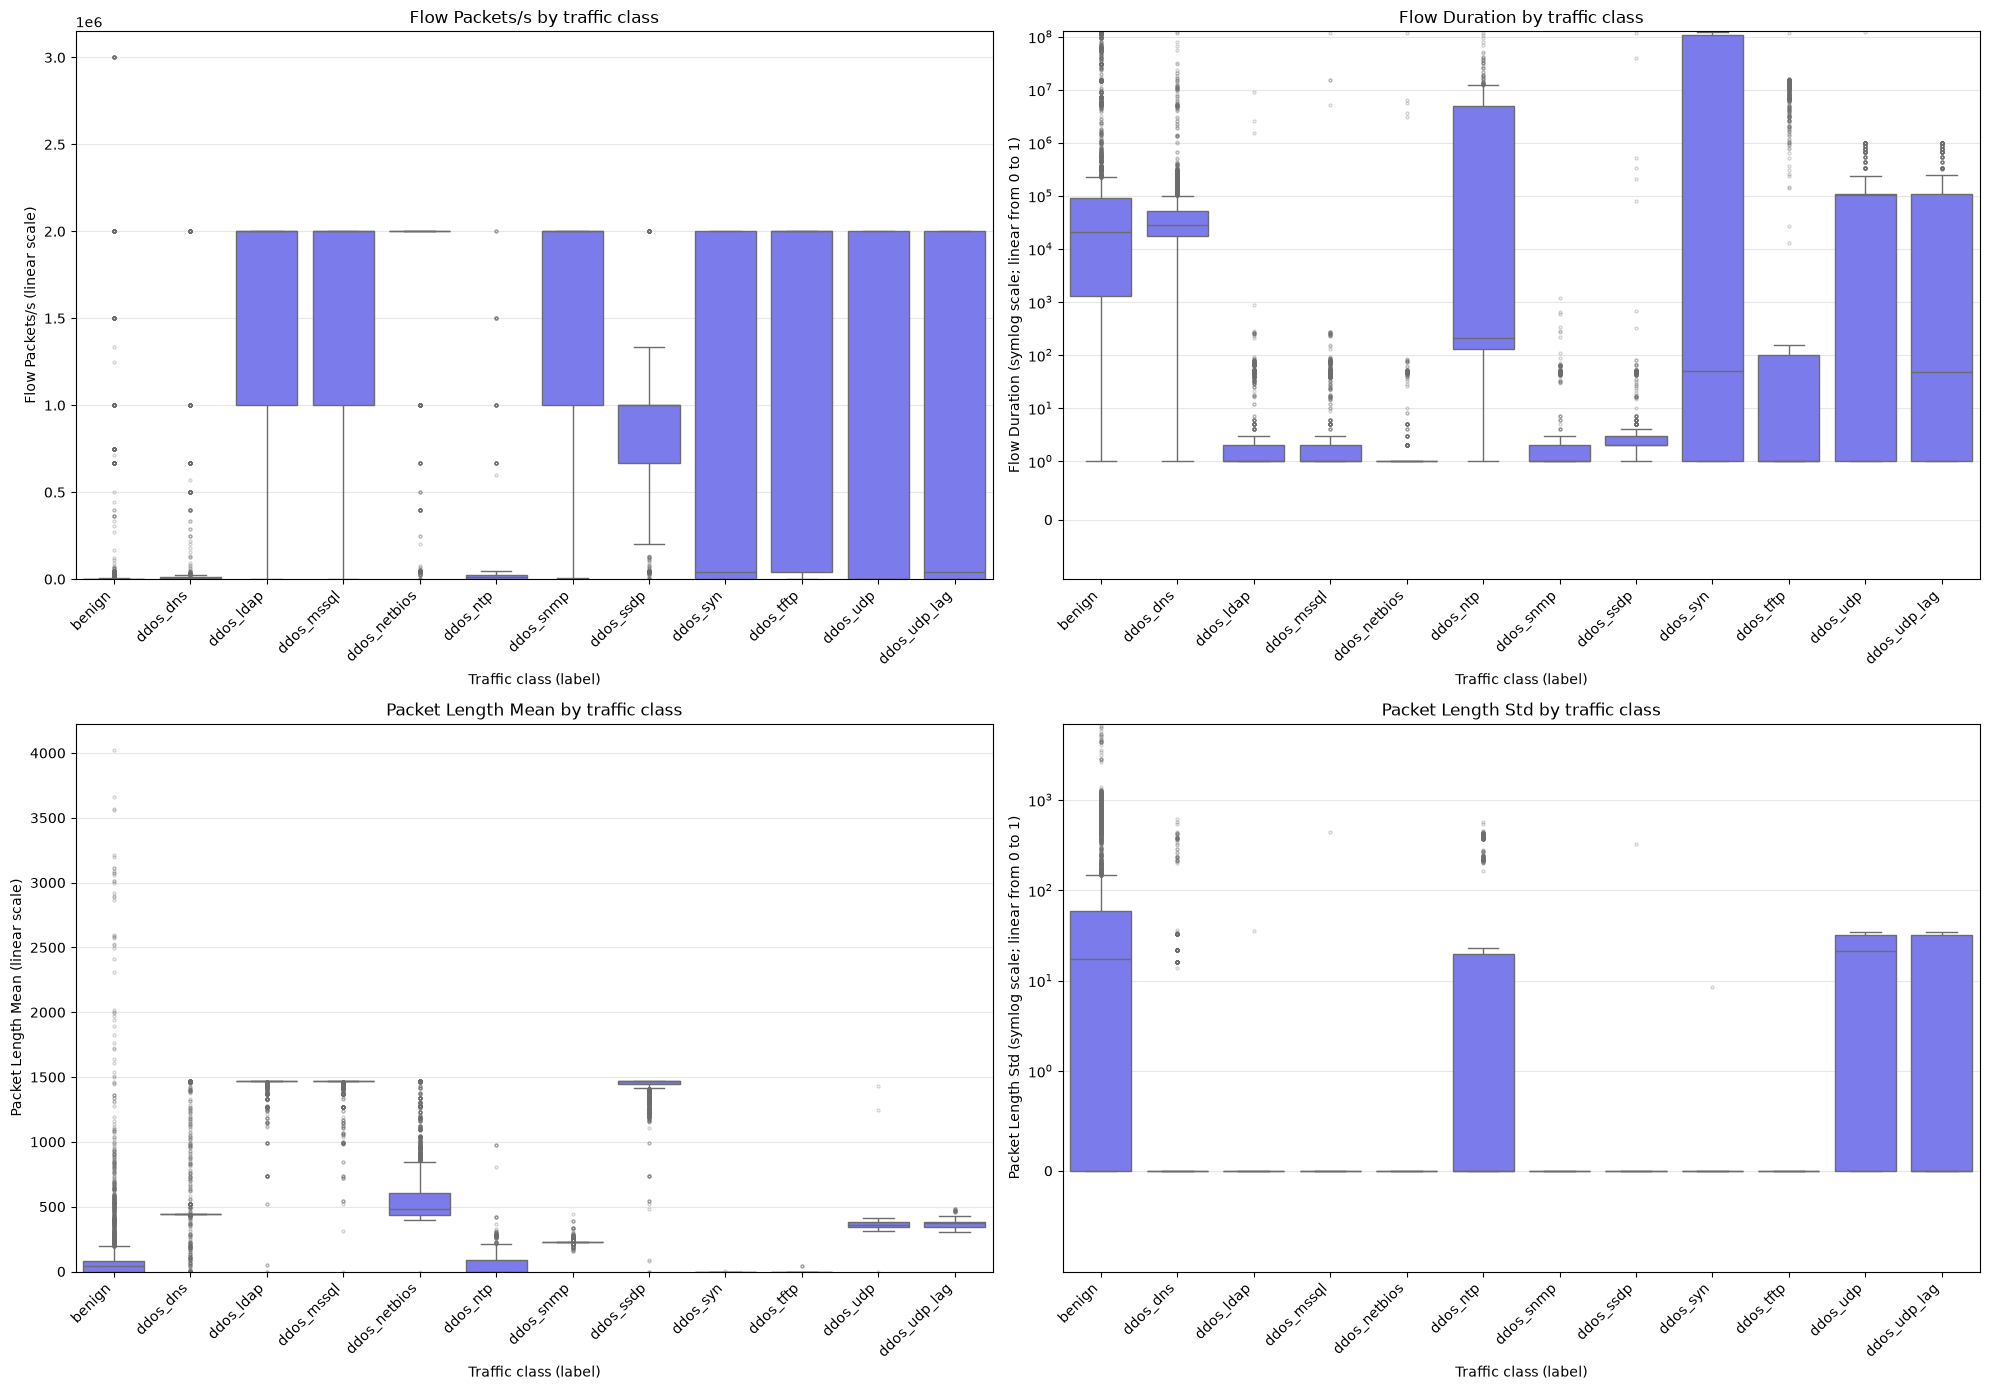

In [9]:
exploration.plot_feature_boxplots(df_stripped)

### Active-period features by traffic class

These box plots compare the mean, standard deviation, maximum, and minimum active-period durations recorded for each flow. For example, a higher median `Active Mean` indicates longer typical active periods in that class; a larger `Active Std` indicates more variation in active-period duration within flows.

Boxes show the middle 50% of flow values, with a line at the median. Strongly skewed features use labeled symmetric logarithmic axes to keep zeros visible. Missing and infinite measurements are excluded locally per feature, leaving the analysis data unchanged. These are timing summaries, rather than packet or byte counts.

The printed summary reports the percentage of all flows within each label with `Active Mean > 0`, sorted from highest to lowest.


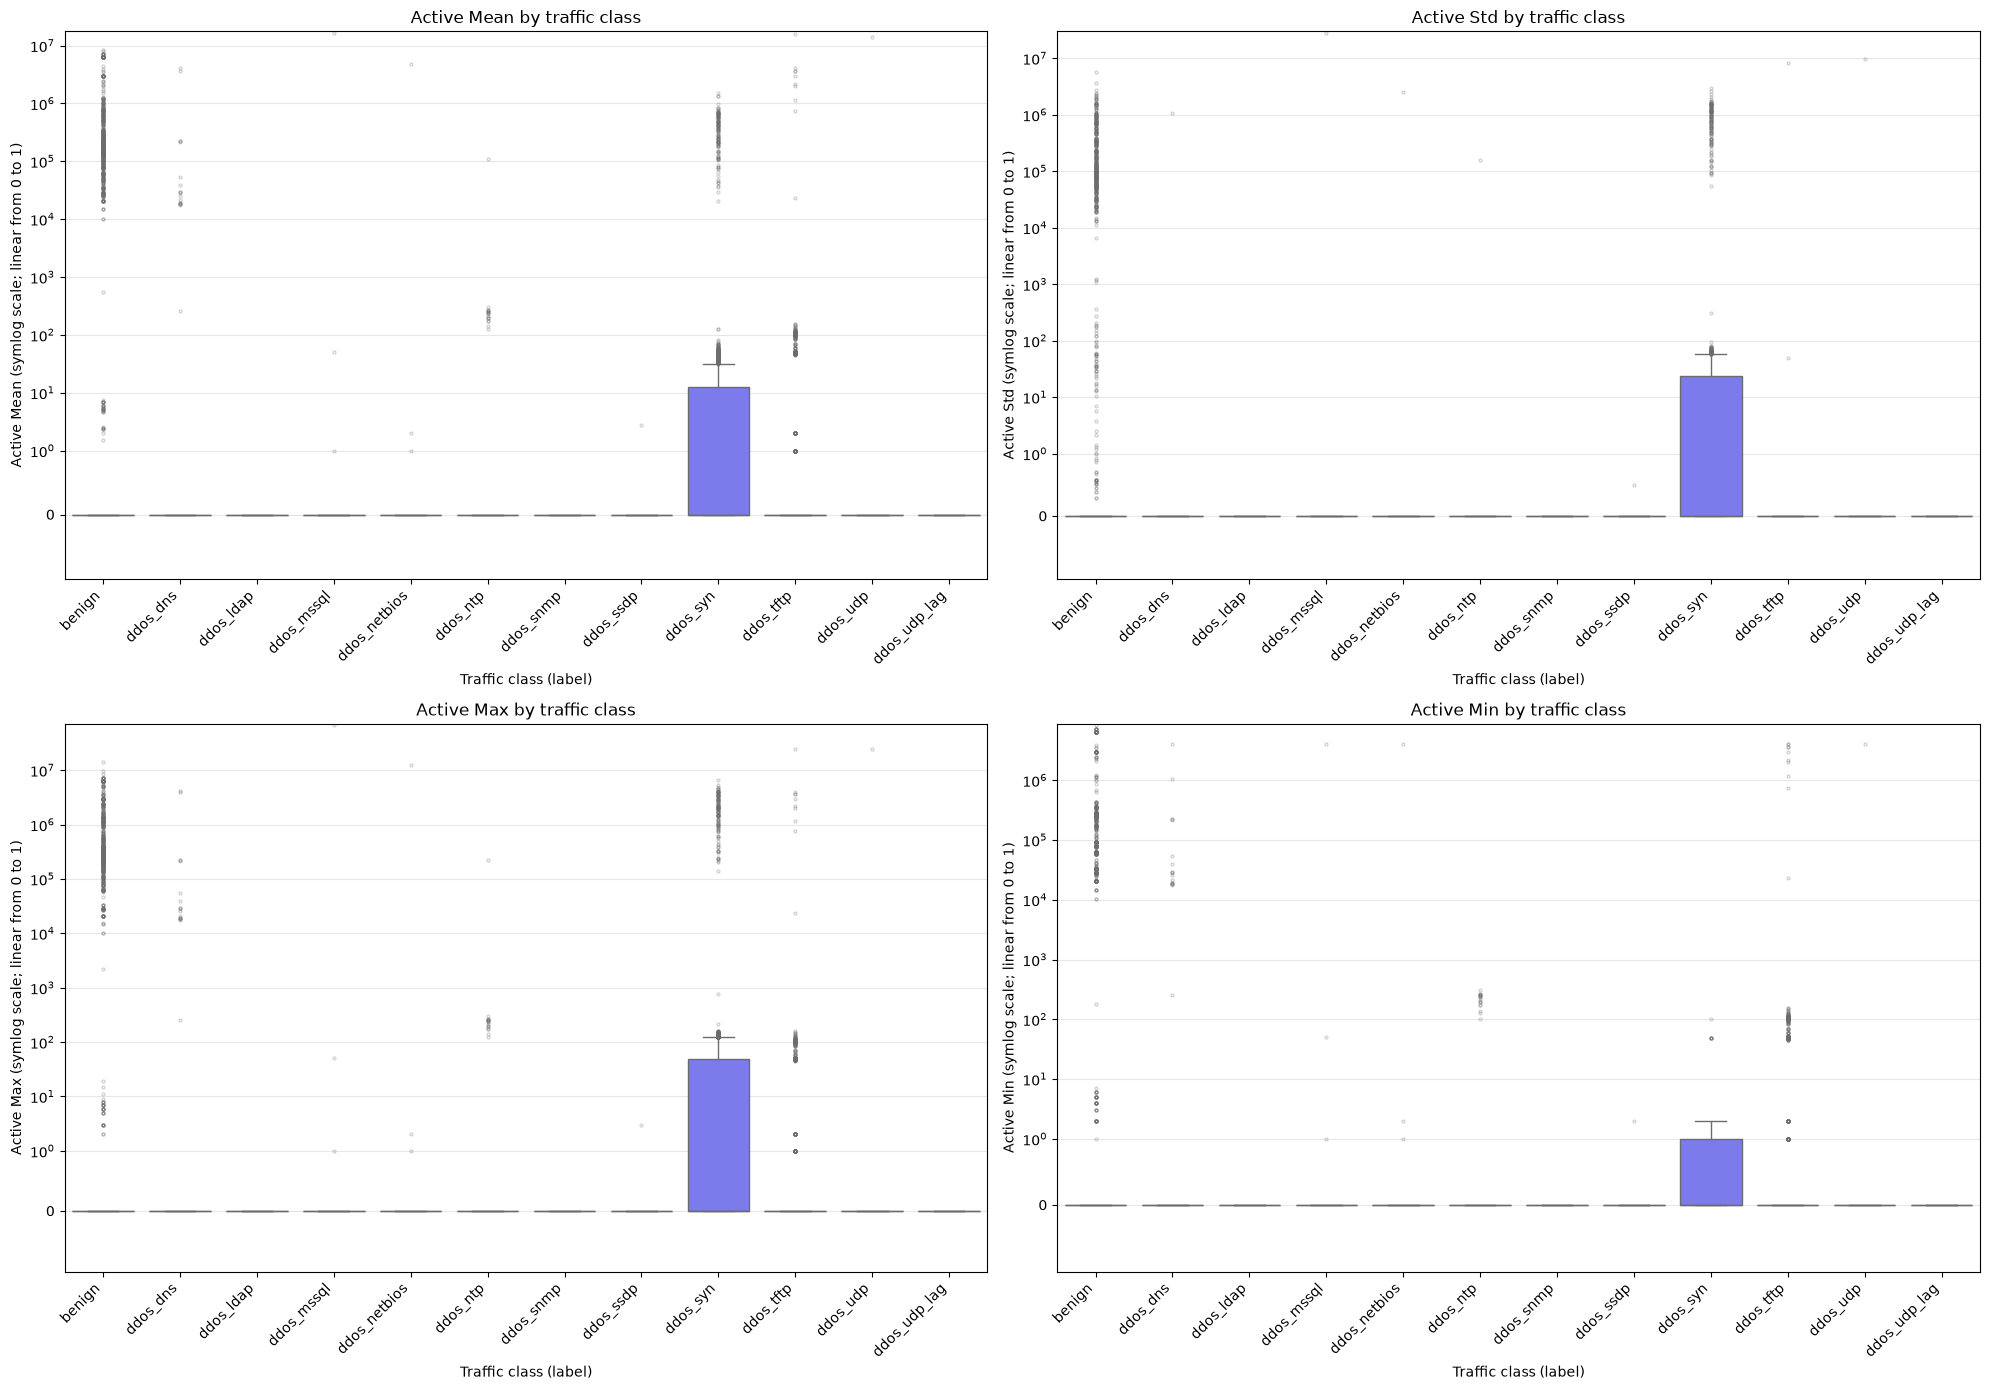

Flows with Active Mean > 0 (% of all flows within each label):
label
ddos_syn       42.26%
ddos_tftp      15.76%
benign         11.49%
ddos_ntp        1.93%
ddos_dns        0.35%
ddos_netbios    0.05%
ddos_mssql      0.05%
ddos_udp        0.02%
ddos_ssdp       0.02%
ddos_ldap       0.00%
ddos_snmp       0.00%
ddos_udp_lag    0.00%


In [10]:
exploration.plot_active_features(df_stripped)

### Histograms by traffic class

Histograms show where values cluster and whether a class has several peaks or long tails. For example, compare where packet rates concentrate for benign traffic and attack classes. Each feature has one panel per class, with shared bins and axes. Bar heights show the fraction of that class in each bin, so classes with different sample sizes remain comparable.

Strongly skewed features use a labeled symmetric logarithmic x-axis and bins spaced to match that scale. Zeros are retained. The plotting copy and per-feature missing-value handling from the box plots are reused.


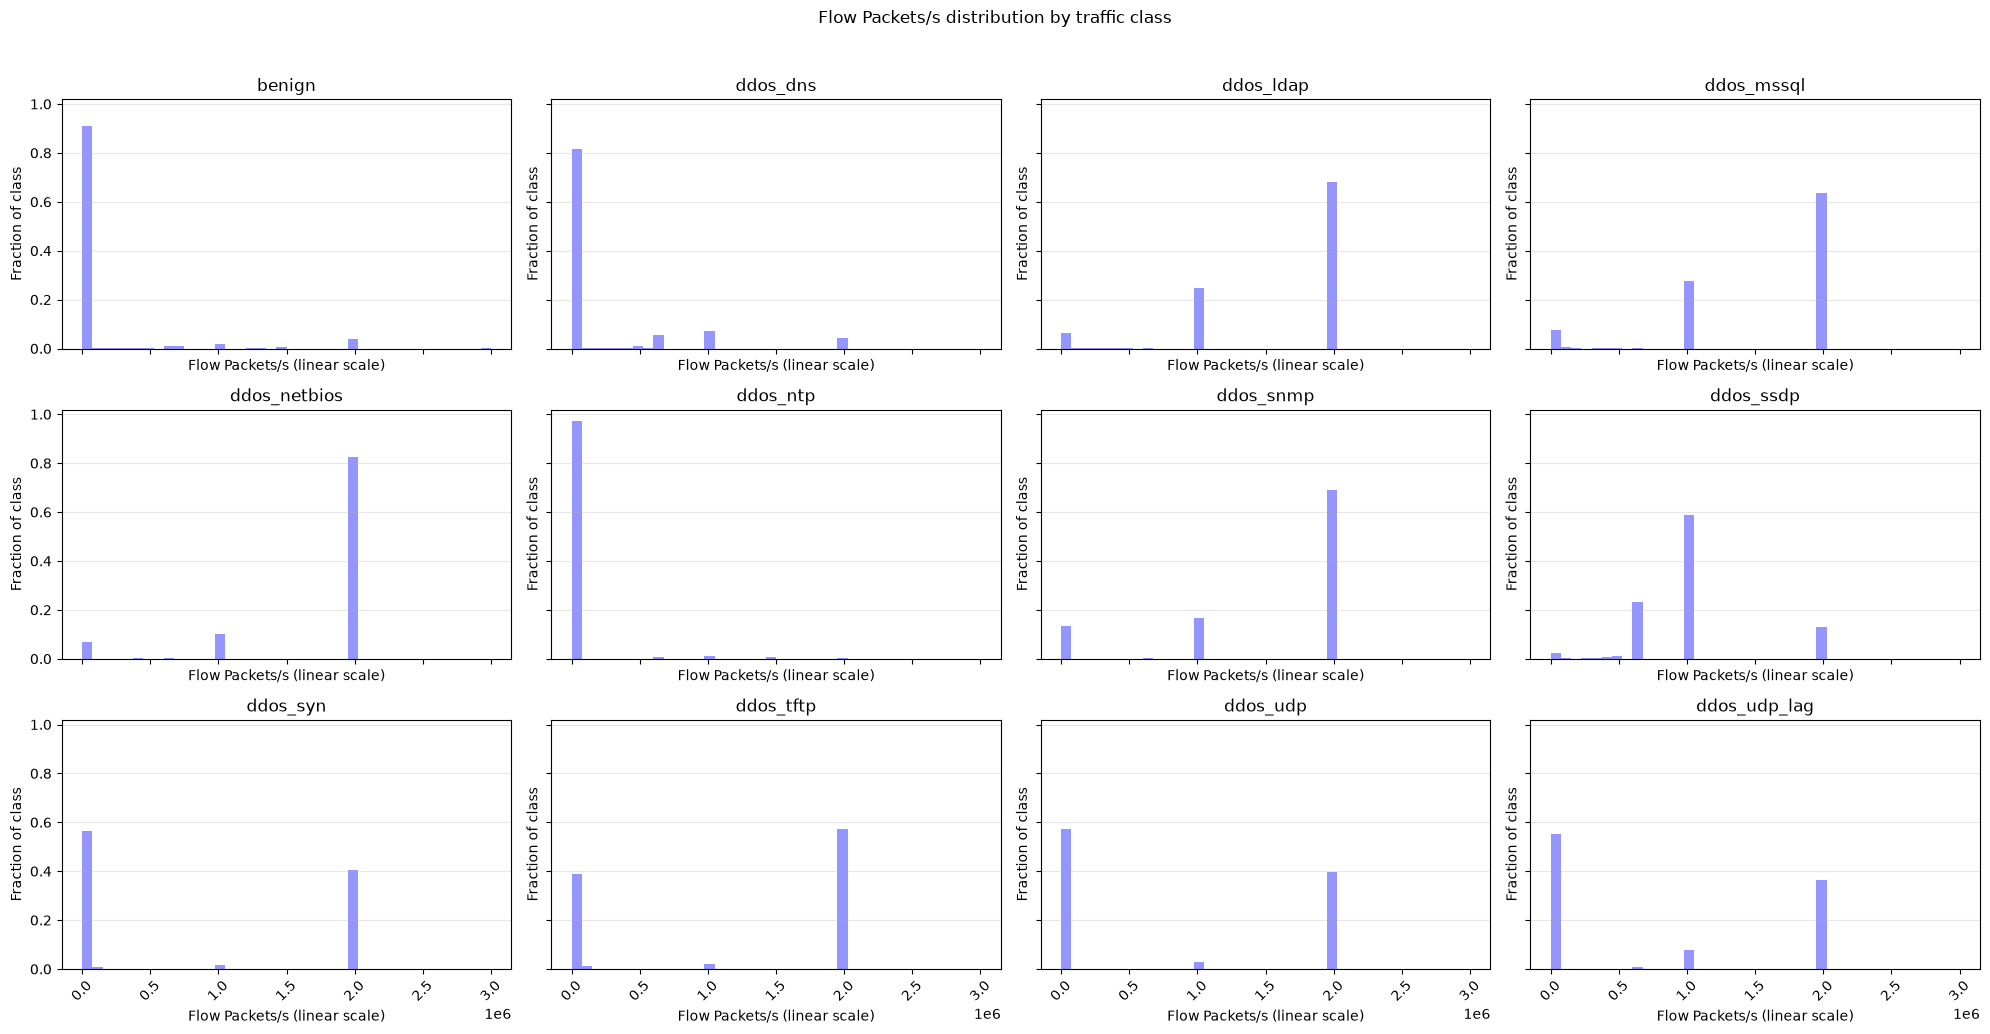

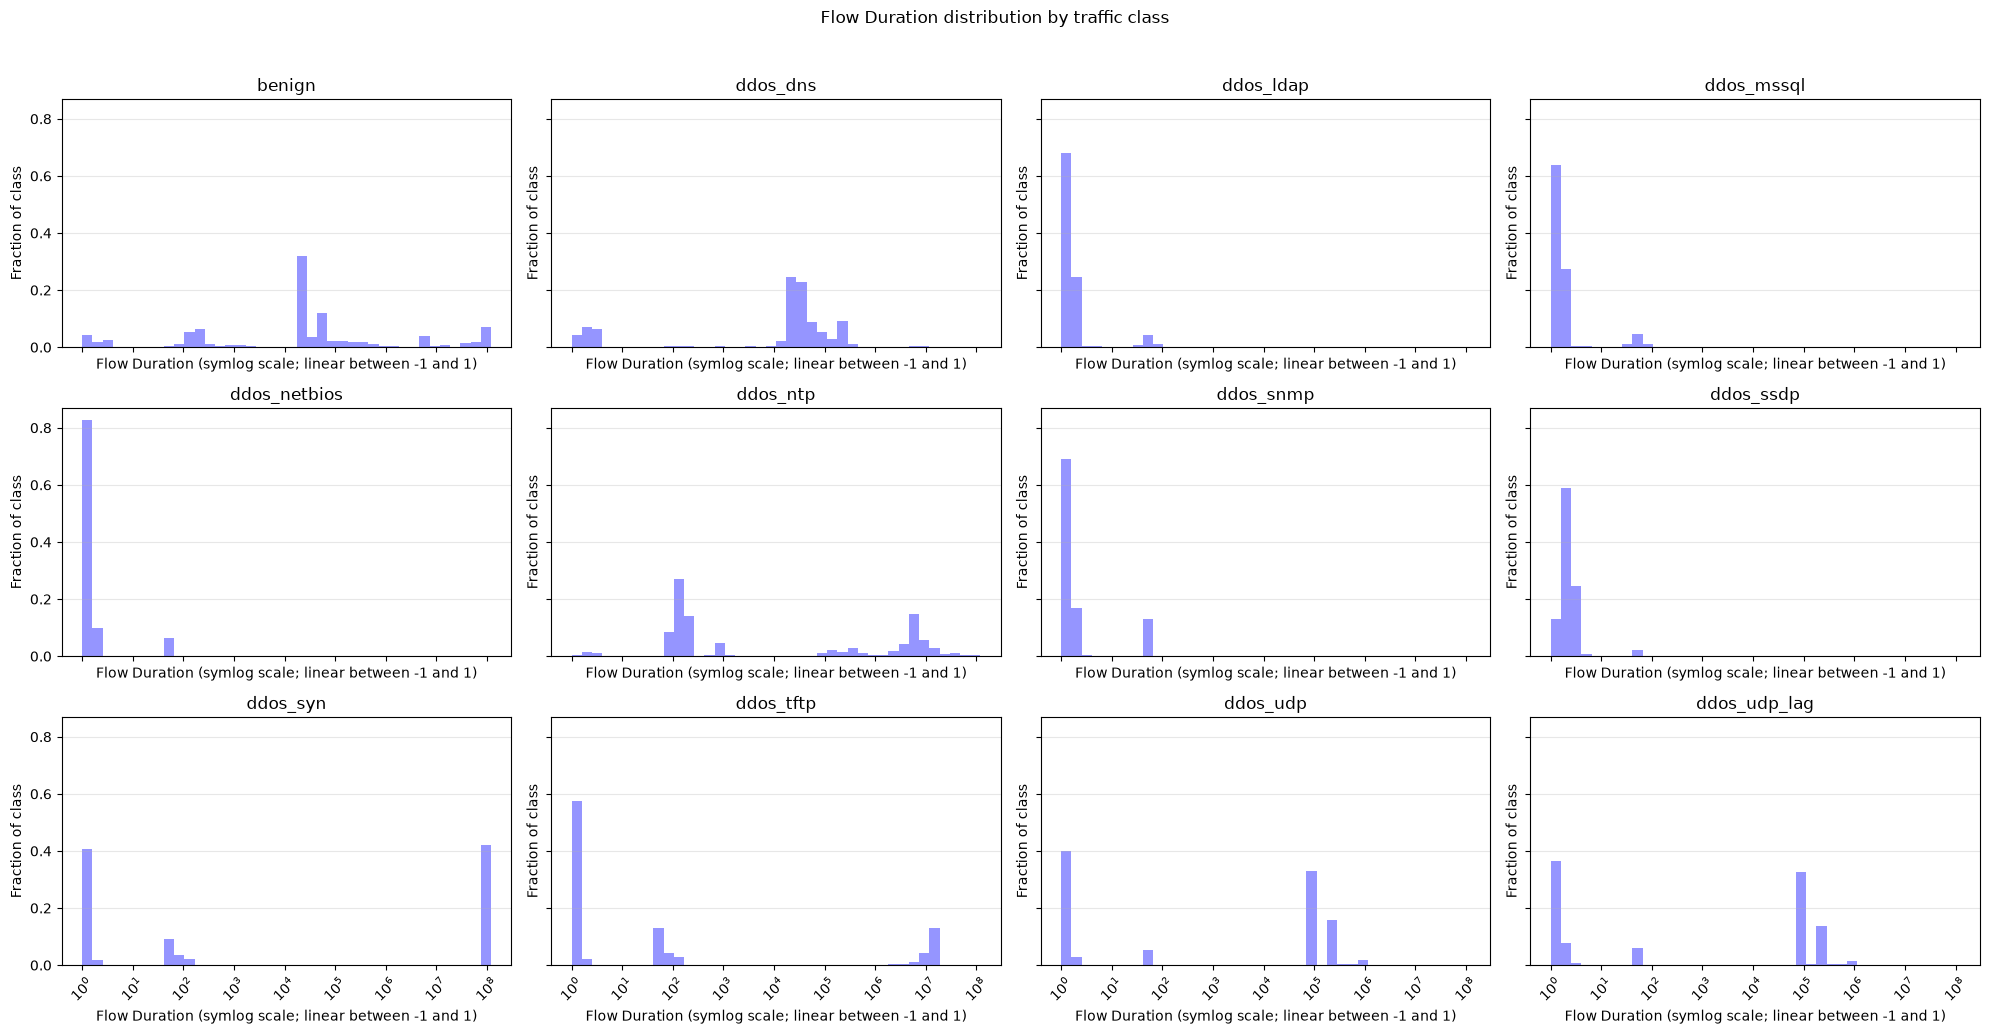

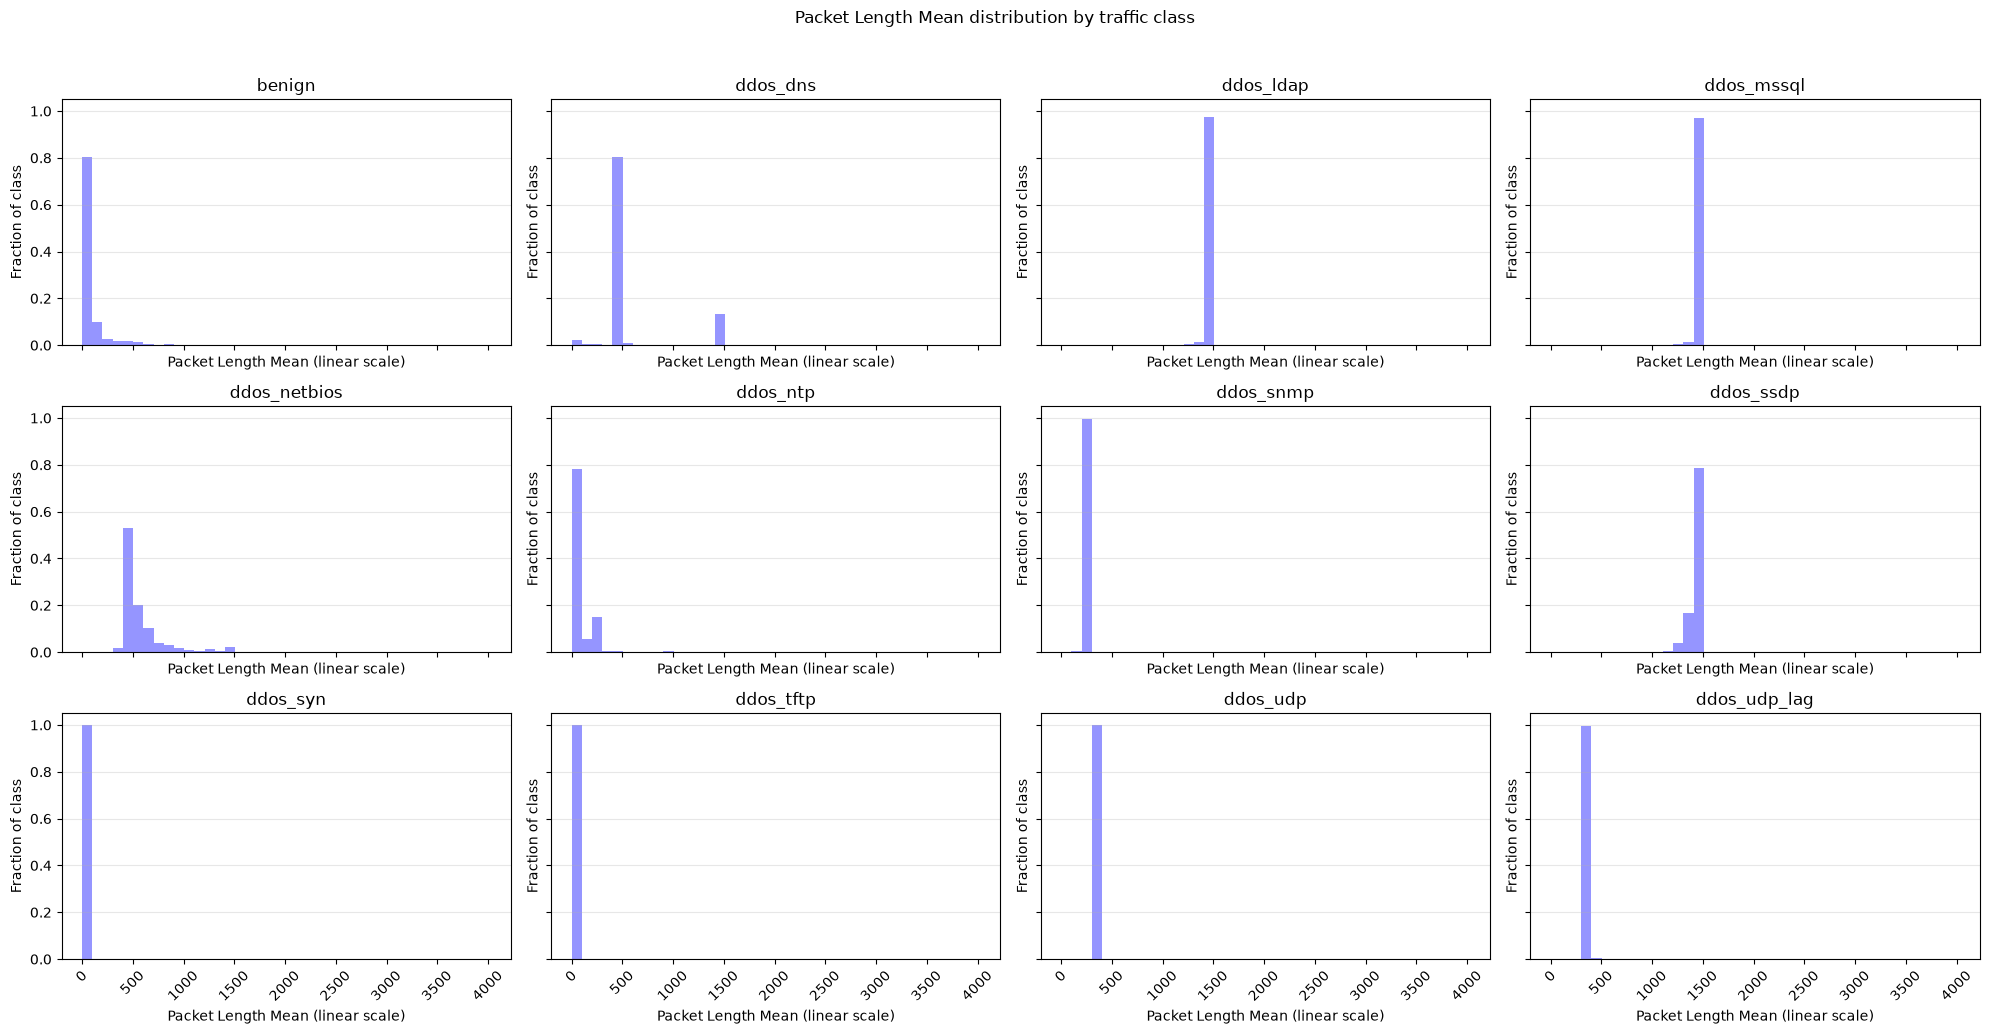

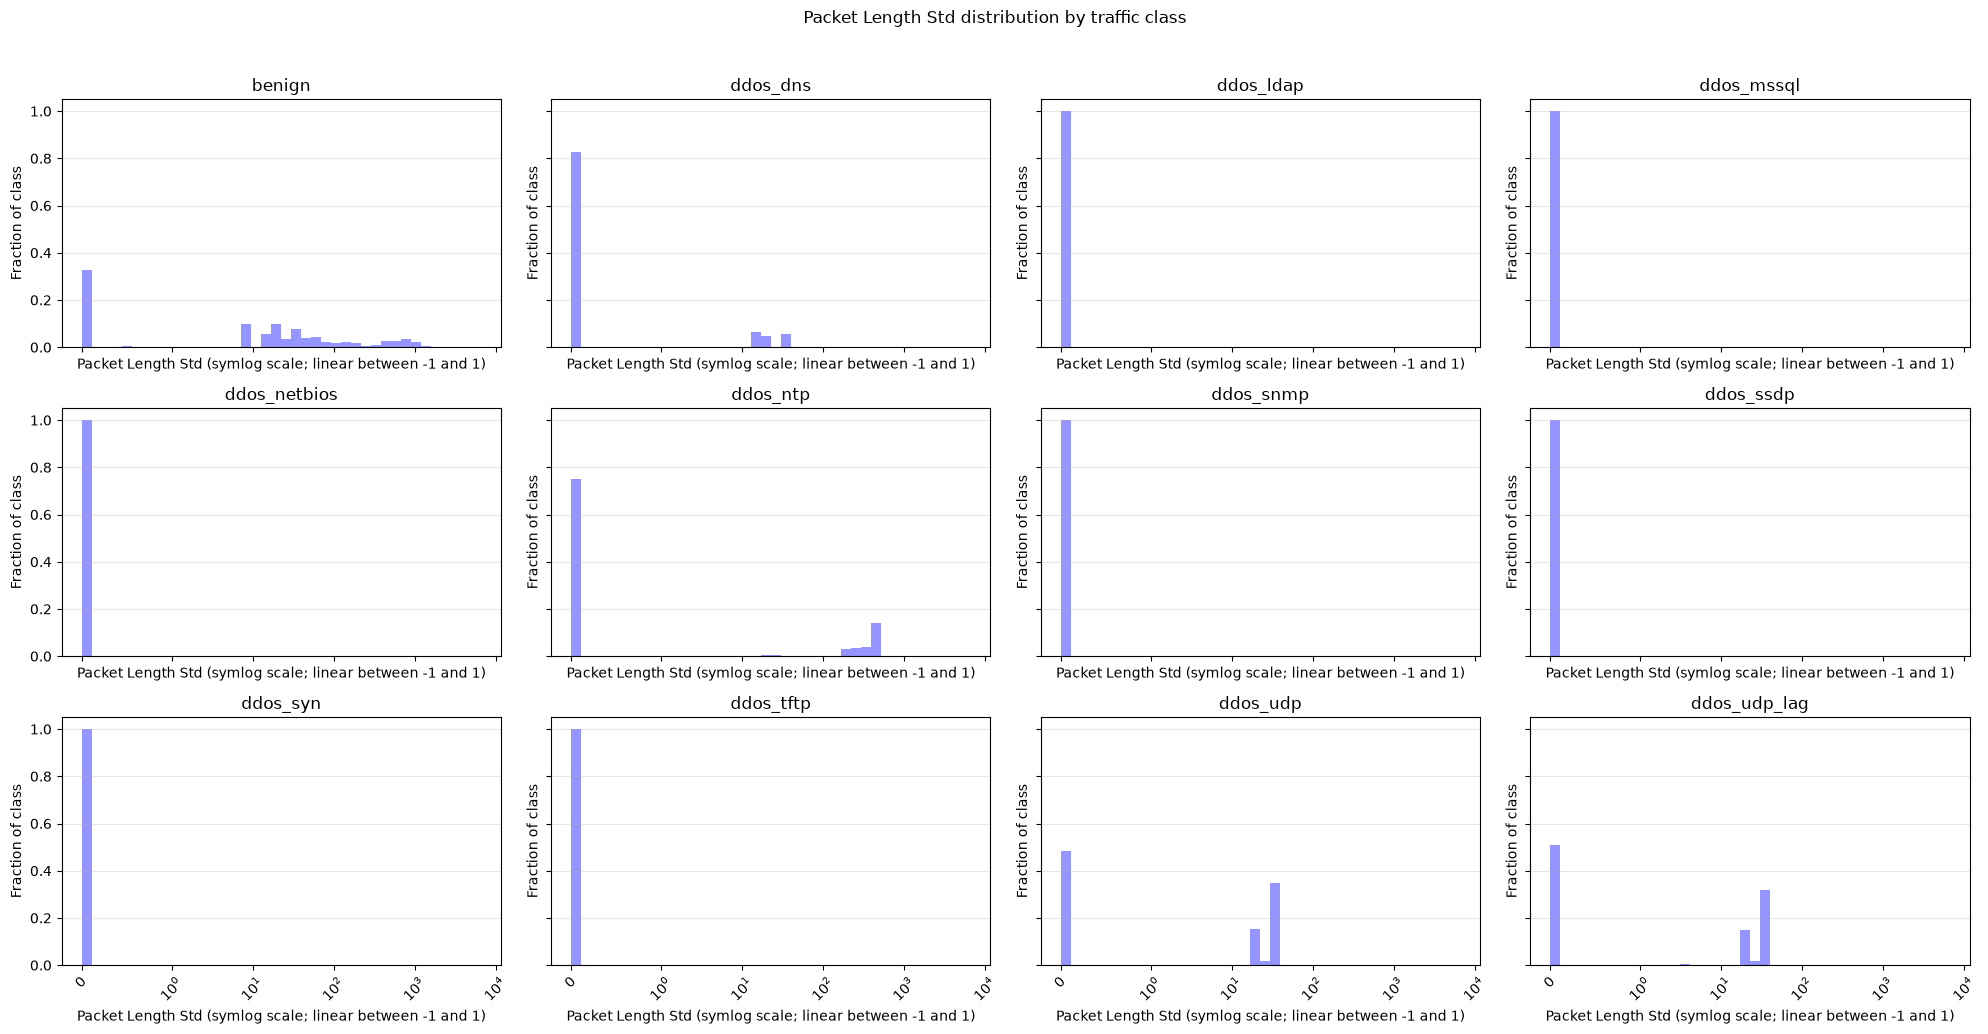

In [11]:
exploration.plot_feature_histograms(df_stripped)

### Forward versus backward byte rates

Separate directional byte rates are not stored in the dataset, so calculate each as total bytes in that direction divided by flow duration in seconds. Converting duration from microseconds reproduces the existing combined `Flow Bytes/s` values. For example, 1,000 forward bytes over half a second gives 2,000 forward bytes/s.

Colors identify traffic classes. Both axes use a symmetric logarithmic scale to show the wide range of rates while retaining zeros. Invalid rates and nonpositive durations are excluded locally; the analysis dataframe is unchanged.


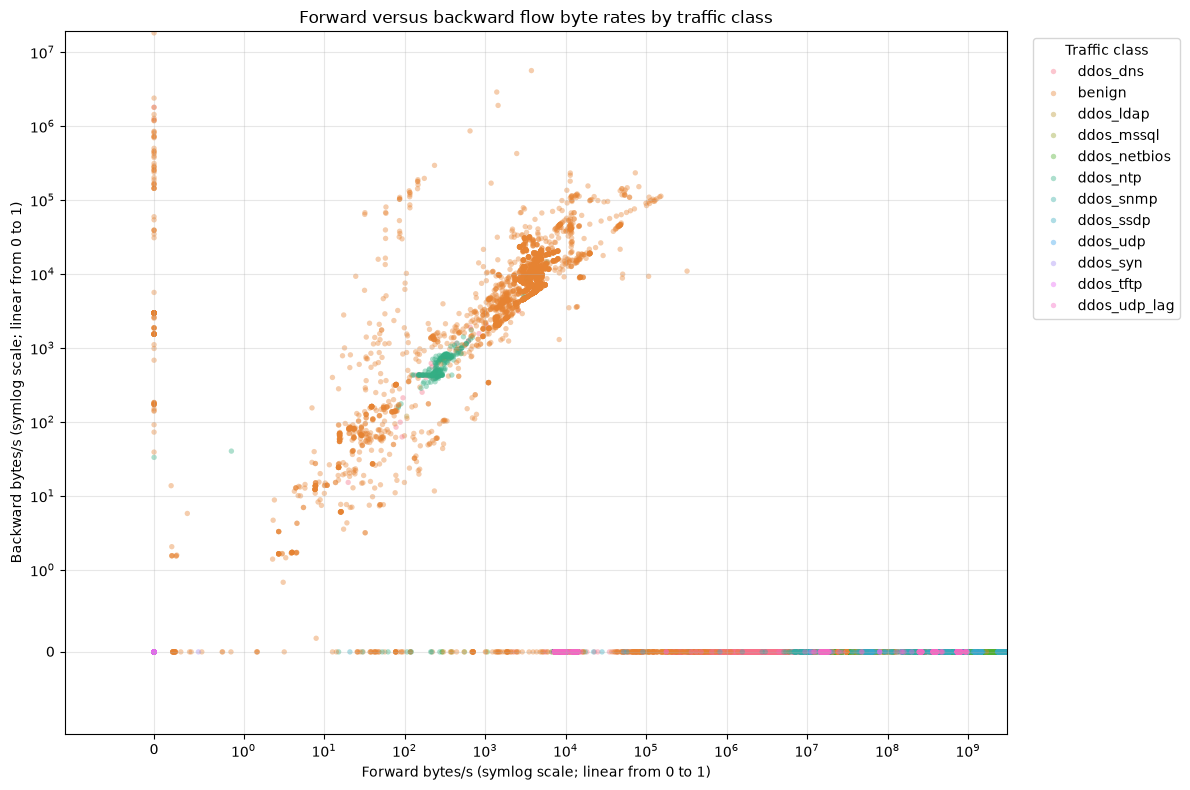

In [12]:
exploration.plot_byte_rates(df_stripped)

### Feature correlations

The matrix shows absolute Spearman correlations between numeric features. Values near 1 indicate a strong monotonic relationship in either direction; values near 0 indicate a weak monotonic relationship. For example, both correlations of +0.9 and -0.9 appear as 0.9 here. Blank cells indicate undefined correlations, such as those involving constant features.


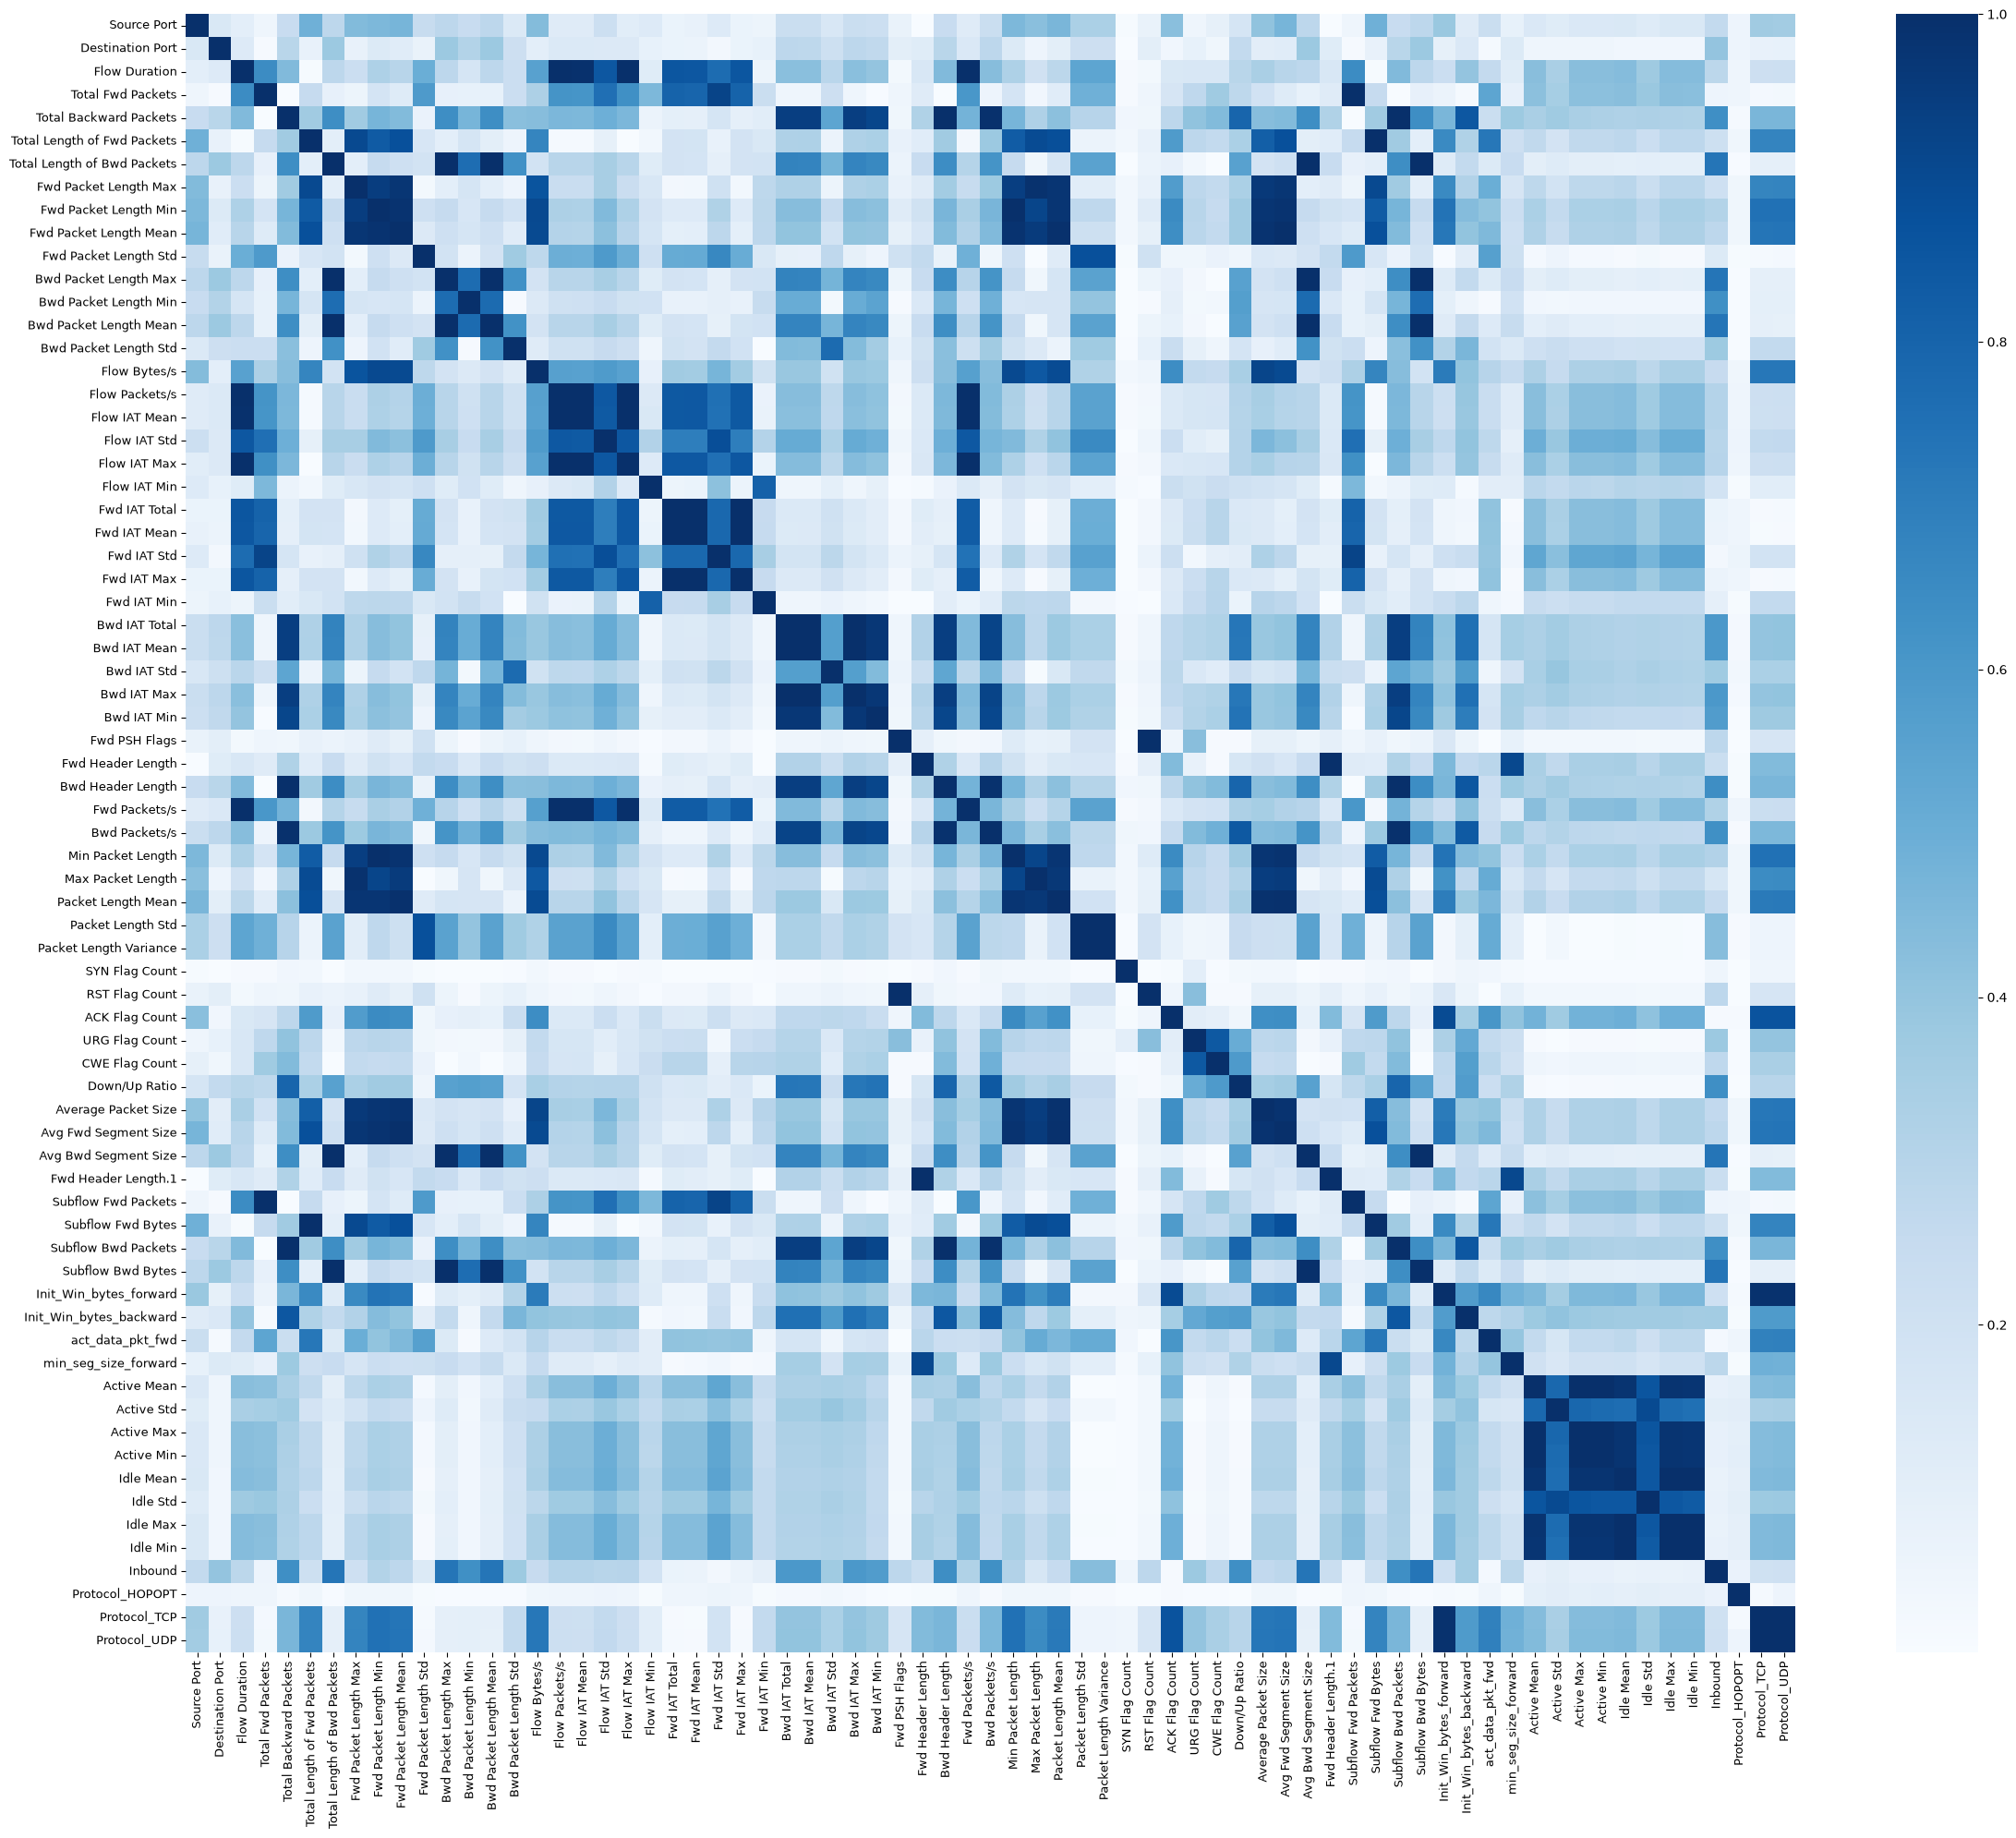

In [13]:
exploration.plot_correlations(df_stripped)

### Remove redundant features

Keep the first quantitative feature in column order and remove later features whose absolute Spearman correlation with a retained feature exceeds 0.9. For example, if A and B have correlation -0.95, keep A and remove B. Comparing only with retained features avoids removing a feature solely because it resembles another feature already removed. The threshold is adjustable. This simple rule depends on column order and can discard useful information, so the table records each removal and its retained counterpart.

Labels, ports, protocol indicators, and `Inbound` remain unchanged because they are categories or identifiers. Keep `df_stripped` for the original plots and use `df_uncorrelated` for the reduced matrix and subsequent PCA.


In [28]:
df_uncorrelated, correlation_removals = exploration.reduce_correlated_features(
    df_stripped, threshold=0.9
)
print(
    f"Removed {len(correlation_removals)} features; {df_uncorrelated.shape[1]} columns remain."
)
display(correlation_removals)

Removed 38 features; 38 columns remain.


,Removed feature,Retained feature,Absolute Spearman correlation
0,Fwd Packet Length Max,Total Length of Fwd Packets,0.904084
1,Fwd Packet Length Mean,Fwd Packet Length Min,0.987166
2,Bwd Packet Length Max,Total Length of Bwd Packets,0.999984
3,Bwd Packet Length Mean,Total Length of Bwd Packets,0.999872
4,Flow Bytes/s,Fwd Packet Length Min,0.902712
5,Flow Packets/s,Flow Duration,0.996758
6,Flow IAT Mean,Flow Duration,0.995619
7,Flow IAT Max,Flow Duration,0.998428
8,Fwd IAT Mean,Fwd IAT Total,0.998426
9,Fwd IAT Std,Total Fwd Packets,0.922406


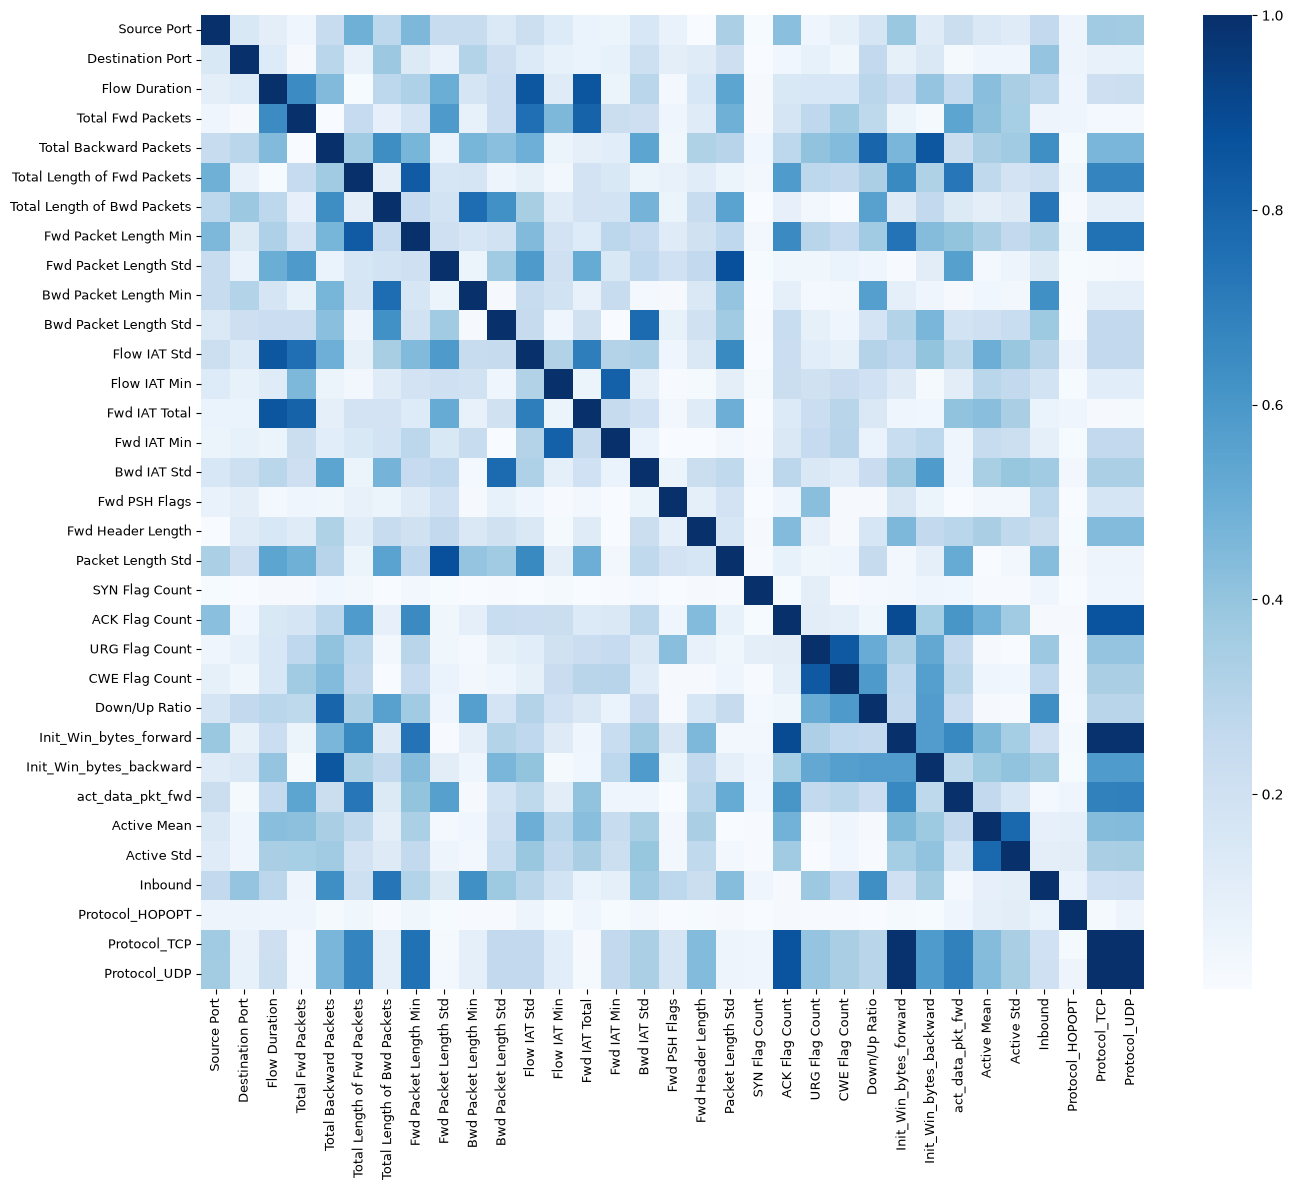

In [ ]:
exploration.plot_correlations(df_uncorrelated, figsize=(14, 12))

### Source and destination port ECDFs

Each curve shows the fraction of flows in a class whose port number is at or below the x-axis value. For example, a value of 0.8 at port 1024 means 80% of that class's flows use ports at or below 1024. Large jumps indicate frequently used ports. Each class is normalized separately, so class sizes do not dominate the comparison.

The x-axes use a symmetric logarithmic scale, linear from 0 to 1, to separate low port numbers while retaining port zero. Port numbers are identifiers; their numeric order helps locate commonly used port ranges. Missing, infinite, and invalid port numbers are excluded separately for each plot in a local copy.


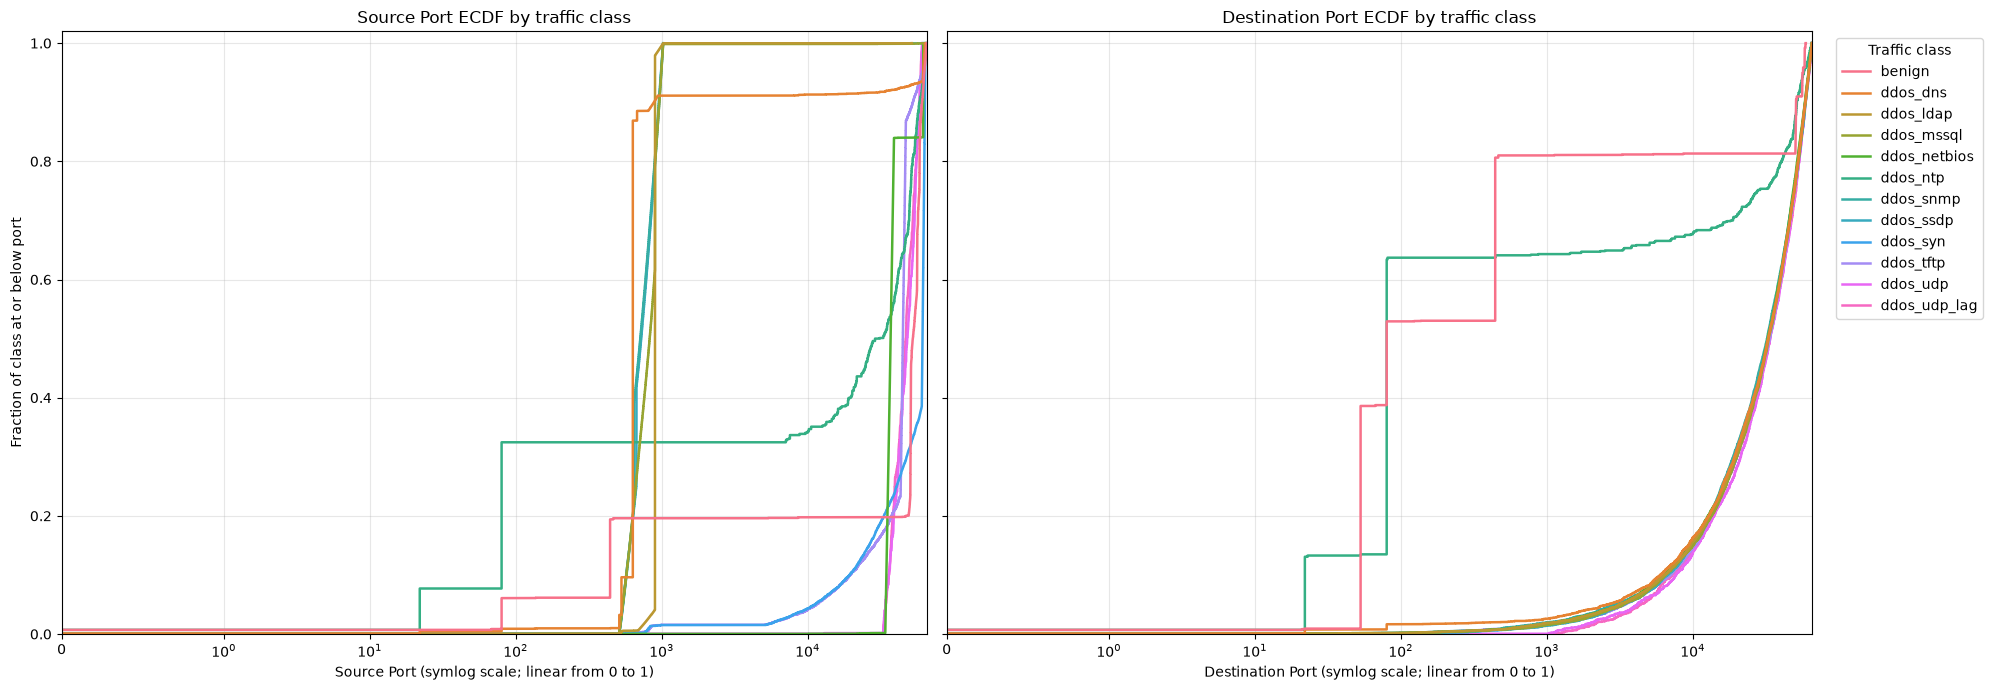

In [16]:
exploration.plot_port_ecdfs(df_stripped)

### Most frequent ports per class

The table lists the five most frequent source and destination ports independently for each class. Percentages use the number of valid ports for that direction within the class. For example, 40% for source port 53 means 40% of that class's valid source-port observations use port 53. Source and destination ports on the same row have the same frequency rank; they are not necessarily from the same flows. Ties are ordered by port number.


In [17]:
port_frequency_table = exploration.show_frequent_ports(df_stripped)

,label,Source port,Source count,Source percent,Rank,Destination port,Destination count,Destination percent
0,benign,443,750,13.26%,1,53,2132,37.68%
1,benign,80,296,5.23%,2,443,1562,27.61%
2,benign,0,40,0.71%,3,80,802,14.17%
3,benign,465,11,0.19%,4,0,40,0.71%
4,benign,50107,9,0.16%,5,465,21,0.37%
5,ddos_dns,634,4149,77.28%,1,80,47,0.88%
6,ddos_dns,530,342,6.37%,2,22,37,0.69%
7,ddos_dns,512,120,2.24%,3,9553,7,0.13%
8,ddos_dns,678,88,1.64%,4,0,4,0.07%
9,ddos_dns,80,23,0.43%,5,42248,4,0.07%


### PCA on quantitative features

Apply PCA only to measurements and counts. Use the quantitative features retained after correlation filtering at the 0.9 threshold. Set aside text fields, the label, ports, protocol indicators, and `Inbound`. A numeric dtype does not make a feature quantitative: for example, port 443 is a service identifier, not a larger amount than port 80. Packet and flag counts remain quantitative here.

Standardize quantitative features before PCA so their units do not dominate. Fit all components to inspect cumulative variance, then retain enough to reach 99% of the standardized quantitative variance. This percentage does not describe prediction accuracy or the categorical fields.

After PCA, append the saved nonquantitative columns unchanged by row index, including the existing one-hot protocol indicators. The resulting `df_pca` contains components and metadata, including `label`; use `X_reduced` for component-only predictors and keep `y` as the target. Do not pass `label` into a classifier's inputs.

This exploratory fit uses the full dataset. For predictive modeling, split first and fit scaling and PCA on training data only. Text and categorical fields would need suitable encoding if used as model inputs later.


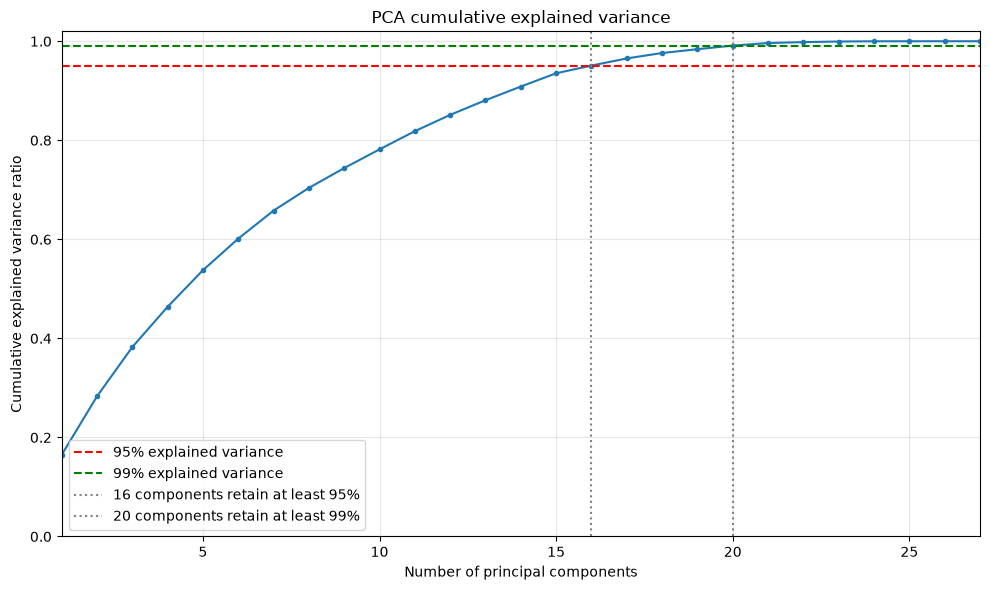

Quantitative features entering PCA: 27
Components needed for at least 95% variance: 16
Components needed for at least 99% variance: 20


In [18]:
analysis = exploration.fit_pca(df_uncorrelated)
exploration.plot_explained_variance(analysis)

In [19]:
df_pca = analysis.df_pca
X_reduced, y = analysis.X_reduced, analysis.y
exploration.show_pca_dataframe(analysis)

Component-only shape: (64239, 20)
Appended nonquantitative columns: ['Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Timestamp', 'SimillarHTTP', 'Inbound', 'label', 'Protocol_HOPOPT', 'Protocol_TCP', 'Protocol_UDP']
Combined dataframe shape: (64239, 31)
Retained quantitative variance: 99.12%


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,Source Port,Destination IP,Destination Port,Timestamp,SimillarHTTP,Inbound,label,Protocol_HOPOPT,Protocol_TCP,Protocol_UDP
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
0,-0.760016,-0.417818,-0.958536,2.018822,-0.227650,-0.290857,-0.066339,-0.052545,-0.016278,0.055034,...,634,192.168.50.1,60495,2018-12-01 10:51:39.813448,0,1,ddos_dns,0,0,1
1,-0.562177,-0.150904,-0.161218,-0.427783,0.101376,0.105546,-0.052822,0.001076,0.050478,0.107774,...,634,172.16.0.5,60495,2018-12-01 10:51:39.820842,0,0,ddos_dns,0,0,1
2,-0.974831,-0.707673,-1.822964,4.671405,-0.584386,-0.720578,-0.080779,-0.110701,-0.088592,-0.002076,...,634,192.168.50.1,46391,2018-12-01 10:51:39.852499,0,1,ddos_dns,0,0,1
3,-0.974846,-0.707697,-1.822963,4.671403,-0.584386,-0.720573,-0.080770,-0.110701,-0.088589,-0.002074,...,634,192.168.50.1,11894,2018-12-01 10:51:39.890213,0,1,ddos_dns,0,0,1
4,-0.975281,-0.708334,-1.822920,4.671325,-0.584403,-0.720493,-0.080471,-0.110728,-0.088502,-0.001968,...,634,192.168.50.1,27878,2018-12-01 10:51:39.941151,0,1,ddos_dns,0,0,1


### PCA scaled loadings

Here, loadings are `pca.components_.T * np.sqrt(pca.explained_variance_)`: each component's feature coefficients multiplied by its standard deviation, with rows in exactly the order of `X_pca.columns`. Use the component variances in `explained_variance_`, not the variance ratios. For example, a coefficient of 0.3 on a component with variance 4 becomes a loading of 0.6. The fitted PCA and preprocessing are reused unchanged.

Larger absolute loadings indicate stronger feature contributions to a component. The bar plots select the 10 largest absolute loadings and preserve their signs. Features with the same sign vary together along that component; opposite signs indicate opposing directions. The overall sign of a component is arbitrary. Scaling by a positive component standard deviation preserves rankings and signs within each PC, while changing magnitudes across PCs.

The heatmap selects the union of the top 10 features from each of PC1–PC5 and displays absolute loadings with `signed=False`. For example, -0.7 is shown as 0.7, so colors compare strength without direction. Use `signed=True` to show signs. These plots describe only the first few PCs, not all the information retained by PCA. PCA ranks directions by variance, not by usefulness for classifying attacks.


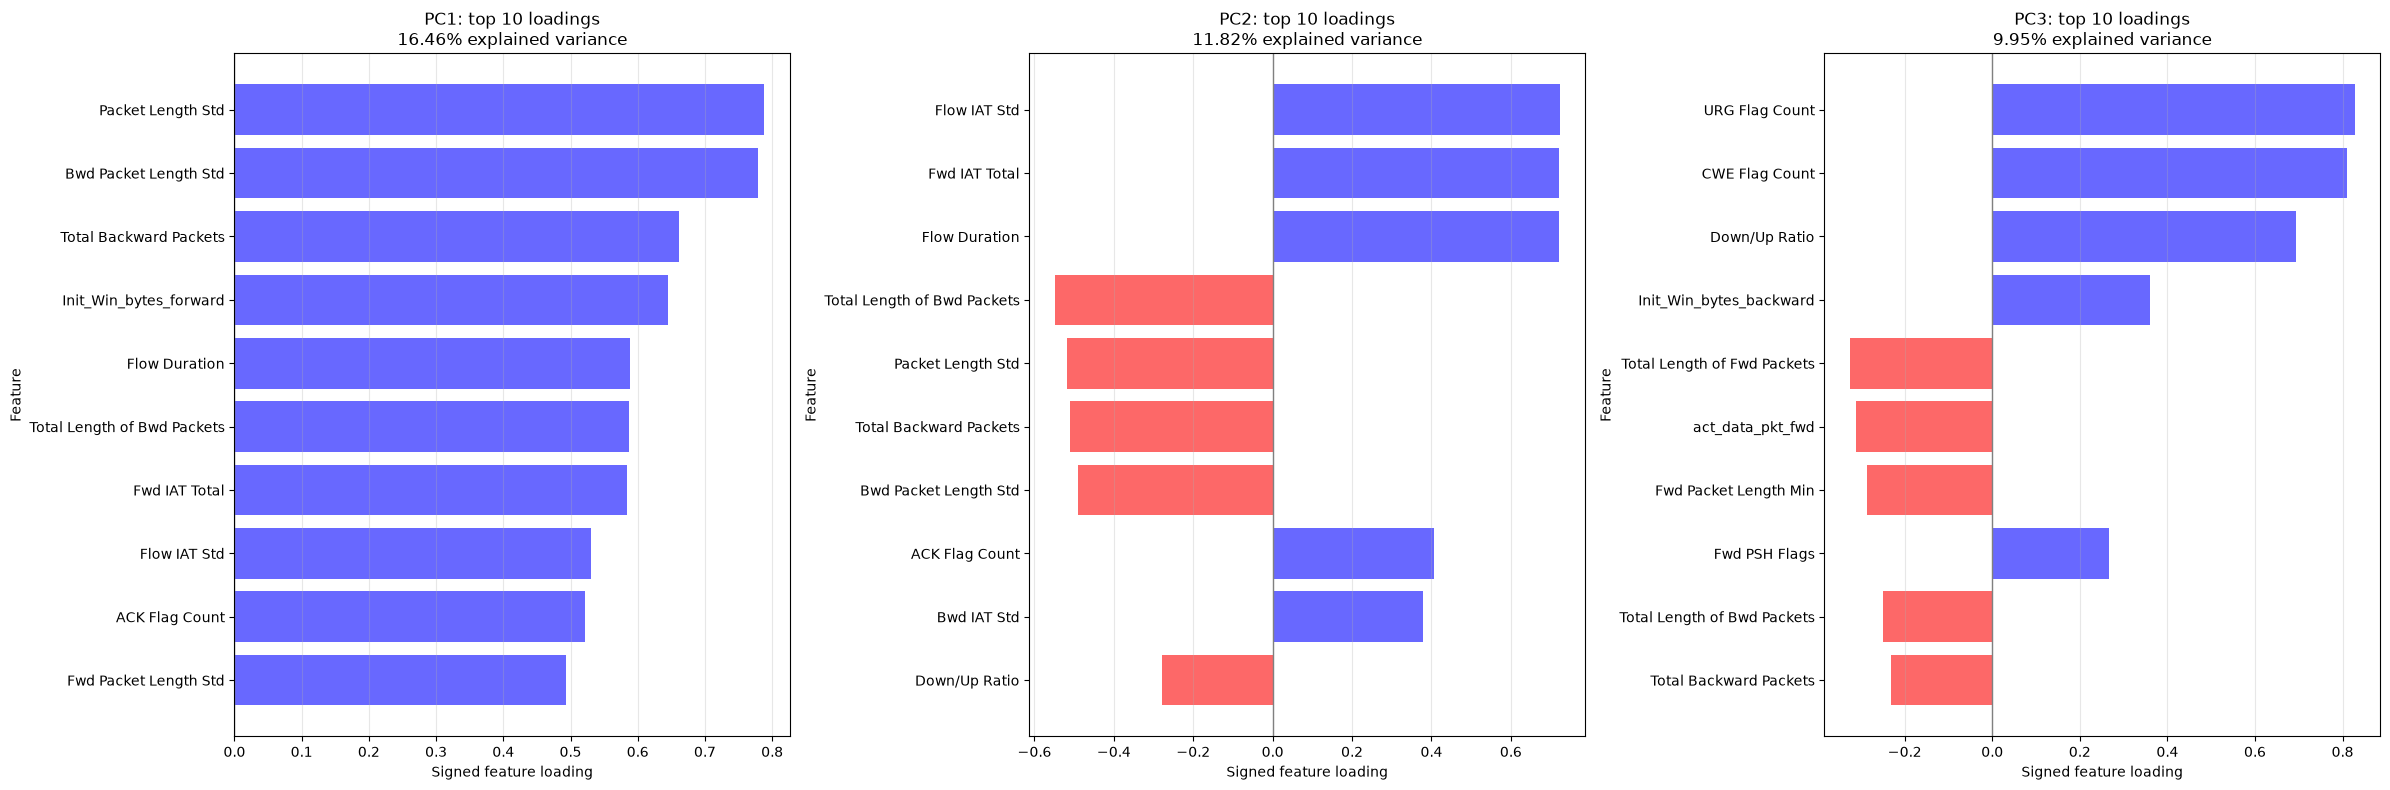

In [20]:
exploration.plot_pca_loadings(analysis)

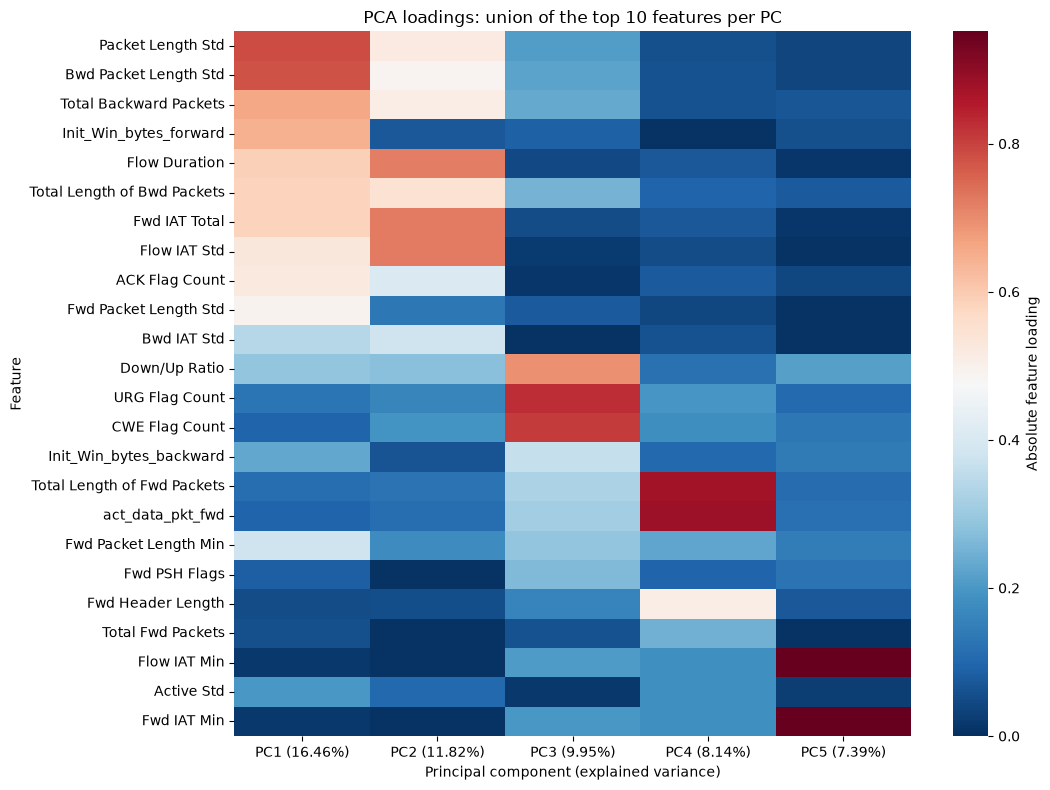

In [21]:
exploration.plot_pca_loadings_heatmap(analysis, signed=False)

The scaled loadings after correlation filtering show the following strongest features:

- **PC1, 16.46% variance:** `Packet Length Std` (+0.787), `Bwd Packet Length Std` (+0.779), `Total Backward Packets` (+0.661).
- **PC2, 11.82% variance:** `Flow IAT Std` (+0.723), `Fwd IAT Total` (+0.722), `Flow Duration` (+0.721).
- **PC3, 9.95% variance:** `URG Flag Count` (+0.828), `CWE Flag Count` (+0.810), `Down/Up Ratio` (+0.693).
- **PC4, 8.14% variance:** `act_data_pkt_fwd` (+0.883), `Total Length of Fwd Packets` (+0.874), `Fwd Header Length` (-0.512).
- **PC5, 7.39% variance:** `Fwd IAT Min` (+0.952), `Flow IAT Min` (+0.950), `Down/Up Ratio` (-0.212).

PC1–PC5 explain 53.76% of standardized quantitative variance after filtering. Same-sign features contribute in the same direction along a component. These patterns do not establish which components best distinguish attack classes.


### PC1 versus PC2 by traffic class

Each point is a flow represented by its existing PC1 and PC2 scores, with color indicating its class. For example, overlapping colors suggest those classes are not clearly separated in these two components. This view shows only part of the retained variance; overlap here does not establish that classes cannot be separated using other components.


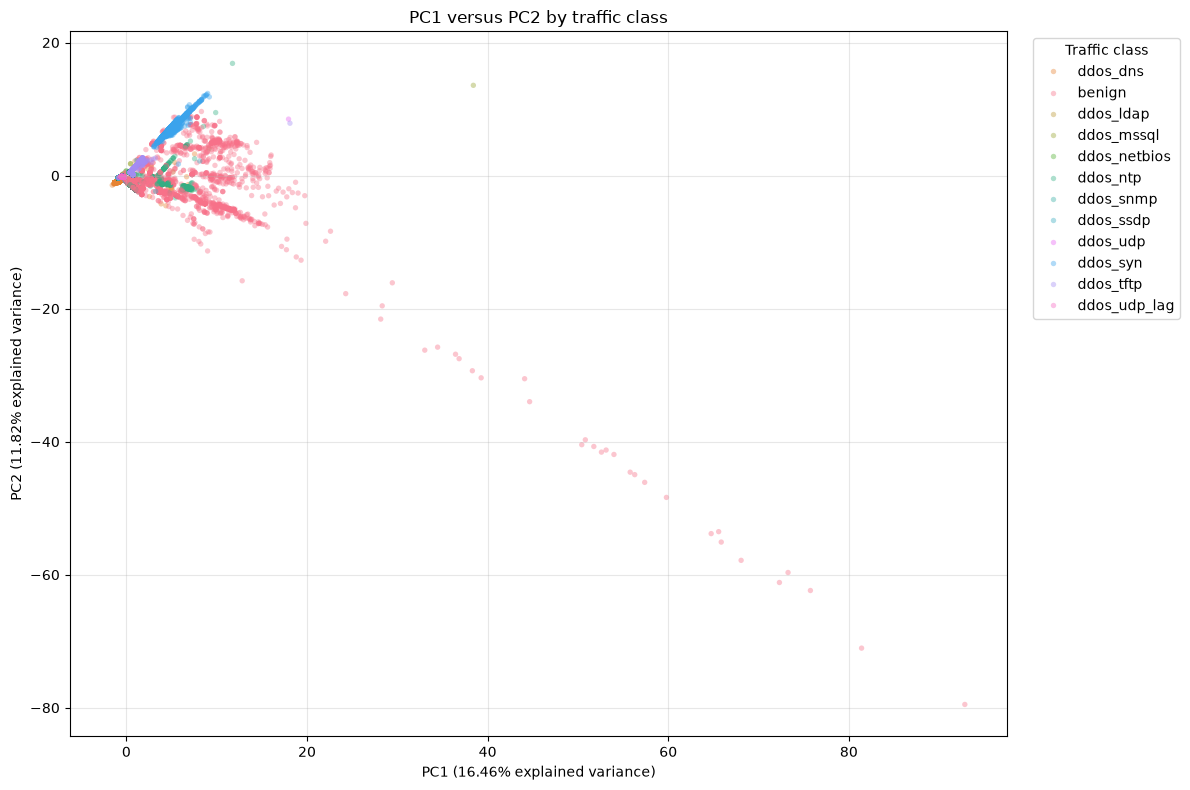

In [22]:
full_pc1_limits = exploration.plot_pca_scatter(analysis)

### Zoomed PC1 versus PC2

A few extreme PC2 scores stretch the full plot's vertical axis and compress the main cloud. This view zooms to the 1st–99th percentile range of PC2 across all flows, making that cloud easier to inspect. For example, classes that look like one overlapping band in the full plot may show more structure when zoomed in.

Only the PC2 axis limits change; PC1 limits, class colors, markers, and legend match the full plot. Points outside the view remain part of the analysis. Counts below and above the displayed range are reported separately.


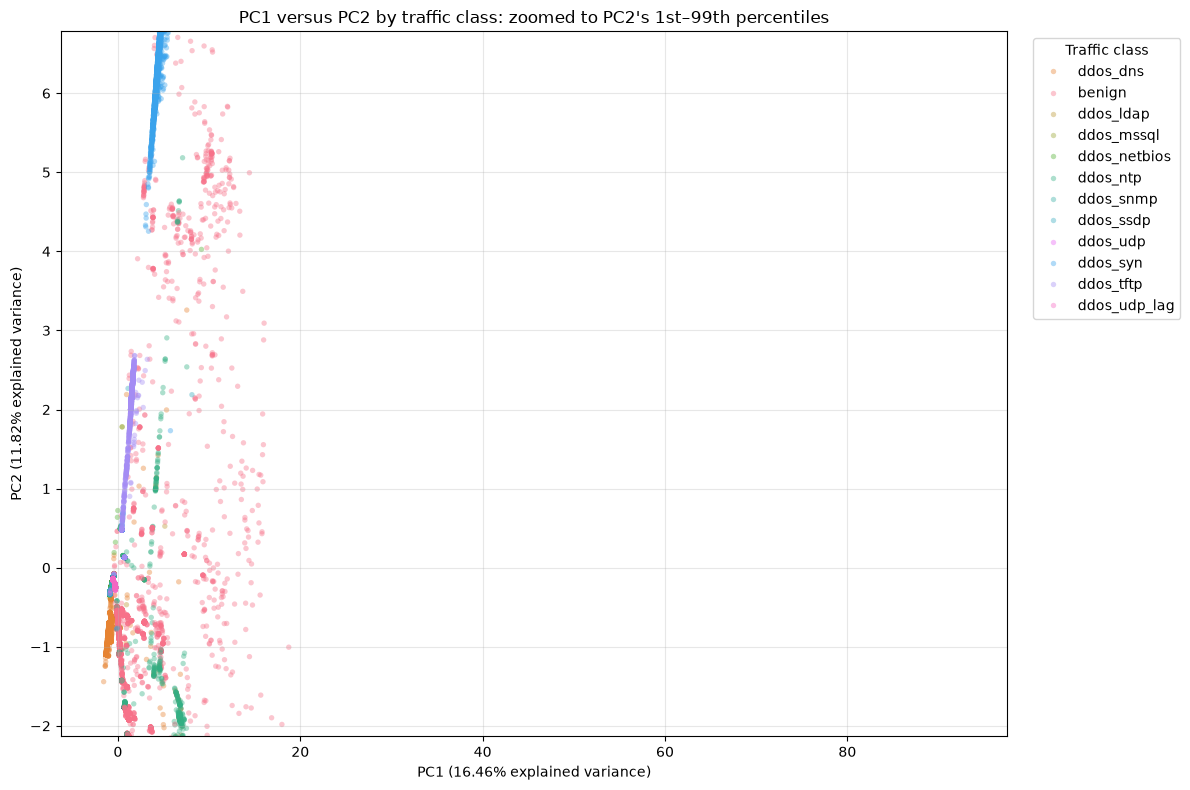

Displayed PC2 range: [-2.13475, 6.7822]
All flows: 64,239
Below range: 643 (1.00%)
Above range: 643 (1.00%)
Total outside view: 1,286 (2.00%)


In [23]:
exploration.plot_pca_scatter(analysis, zoom=True, xlim=full_pc1_limits);

### Benign traffic in the same PCA zoom

This view shows only benign flows using the existing PCA scores. It keeps the same PC1 limits, PC2 percentile limits calculated across all classes, and benign color as the preceding plot. For example, compare its shape with the benign points in the all-class view to see where normal traffic lies without other classes obscuring it. Points outside the zoom remain in the analysis.


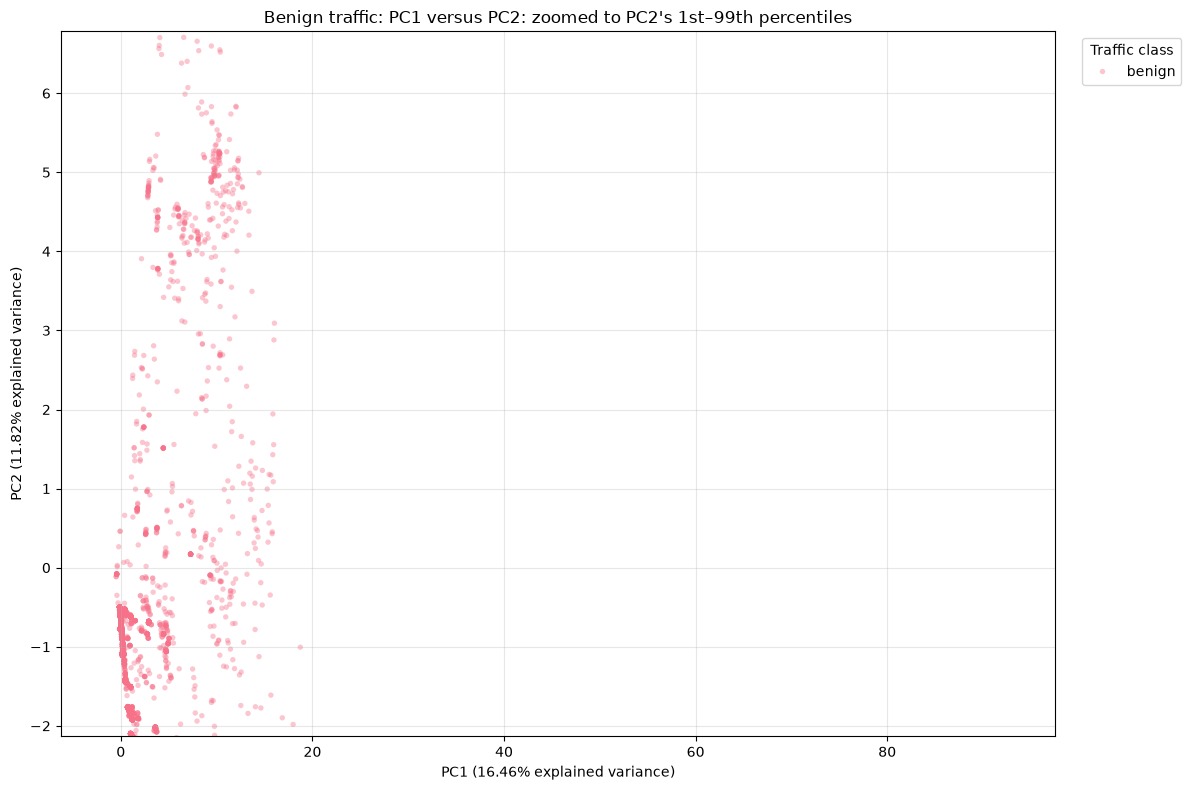

Displayed PC2 range: [-2.13475, 6.7822]
Benign flows: 5,658
Below range: 627 (11.08%)
Above range: 48 (0.85%)
Total outside view: 675 (11.93%)


In [24]:
exploration.plot_pca_scatter(analysis, group="benign", zoom=True, xlim=full_pc1_limits);

### DDoS traffic in the same PCA zoom

This view includes all DDoS classes and excludes benign flows. It uses the same axes, class colors, and marker settings as the benign-only and all-class zoomed views. For example, compare the DDoS cloud with the benign-only cloud to inspect where their PC1 and PC2 scores overlap. The percentile limits still come from all flows, and points outside the view remain part of the analysis.


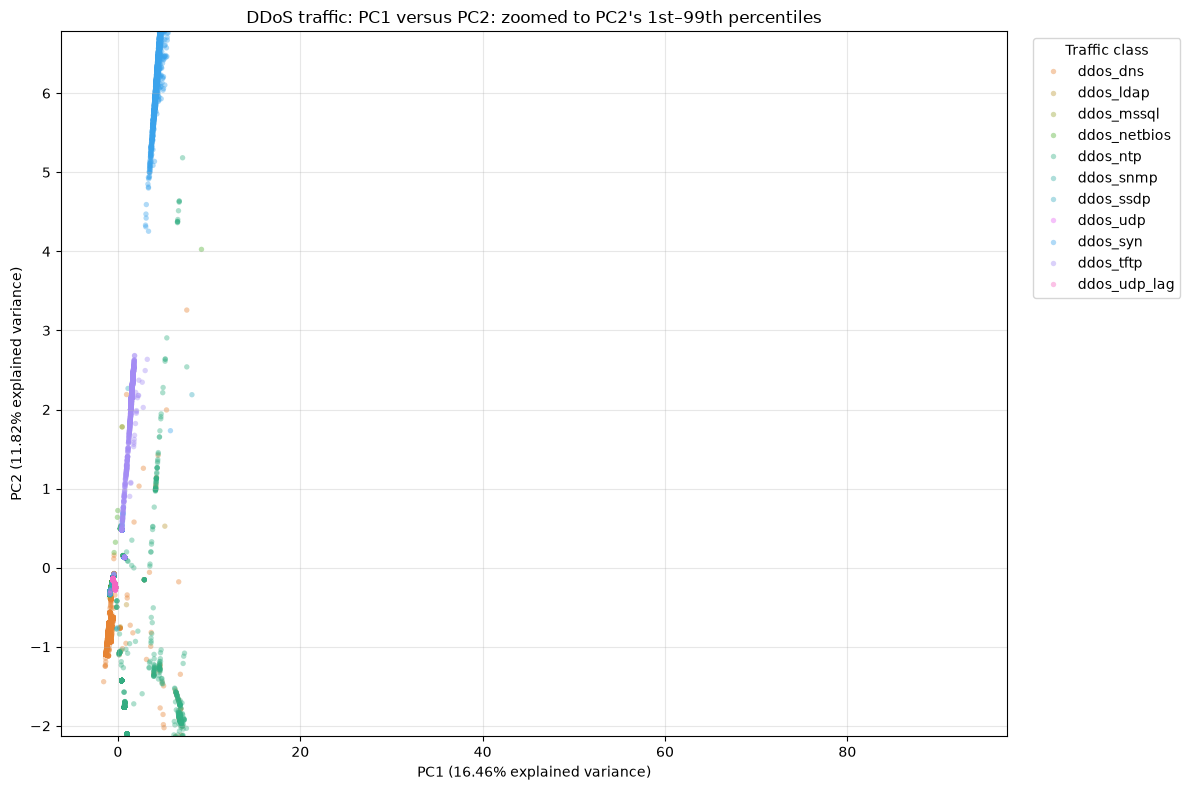

Displayed PC2 range: [-2.13475, 6.7822]
Ddos flows: 58,581
Below range: 16 (0.03%)
Above range: 595 (1.02%)
Total outside view: 611 (1.04%)


In [25]:
exploration.plot_pca_scatter(analysis, group="ddos", zoom=True, xlim=full_pc1_limits);

### PC1 distribution by traffic class

These overlaid histograms use shared bins and consistent class colors. Each class is normalized to total area 1, making distribution shapes comparable despite different class sizes. For example, peaks at different PC1 values suggest that those classes tend to have different scores on this component. PC1 scores can be negative, so the x-axis remains linear.


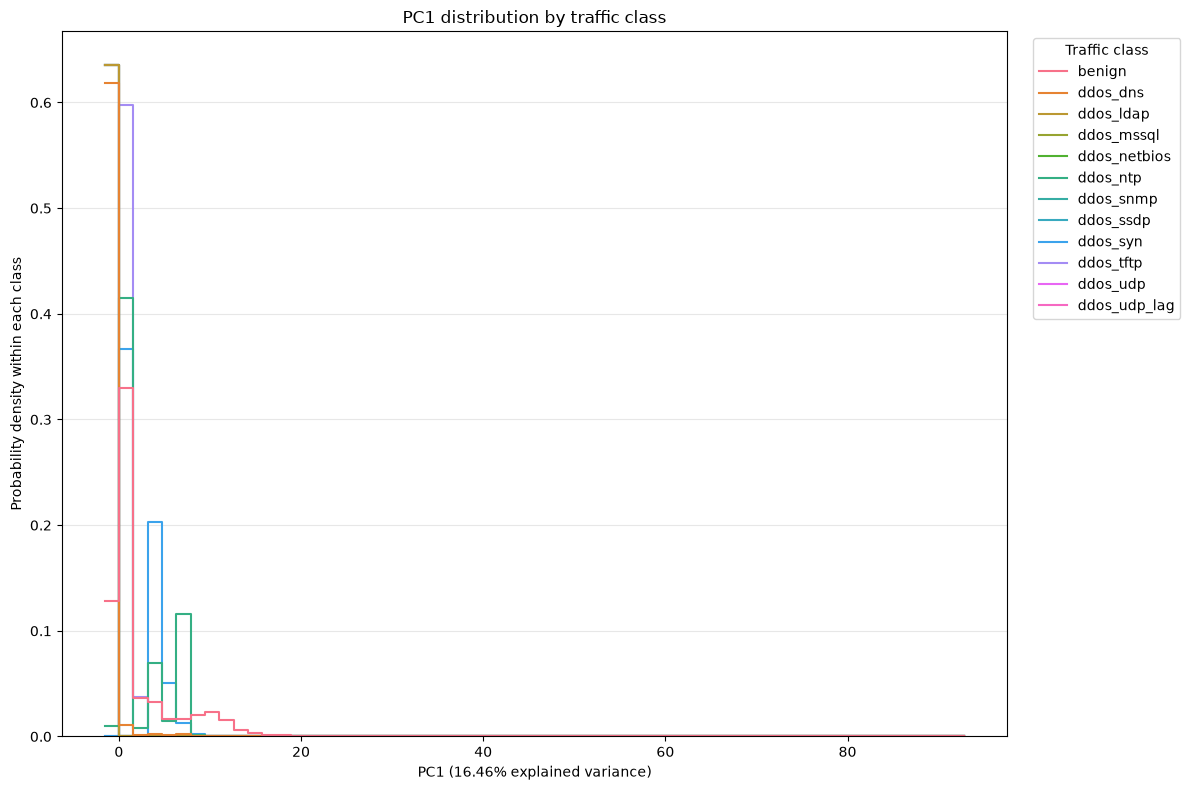

In [26]:
exploration.plot_pc1_histogram(analysis)